## PestCLEF: как из текста получился граф знаний

В этой работе извлекаем из документа сущности и направленные отношения между ними. На входе текст о вредителях растений. На выходе список троек вида «субъект, предикат, объект», например `(Pest, Located_in, Location)` на уровне типов. Предикат задаёт смысл и направление связи. Перестановка субъекта и объекта меняет утверждение.

Корпус содержит 110 документов train, 55 dev и 82 test. Для локального обучения и проверки мы объединяем 165 размеченных документов train и dev. Test используется для подготовки файла ответа. Схема различает 7 типов сущностей: Pest (вредитель), Plant (растение), Disease (болезнь), Vector (переносчик), Location (место), Date (дата), Dissemination_pathway (путь распространения). Для них заданы 7 предикатов и 20 допустимых сочетаний «предикат, тип субъекта, тип объекта».

В книге Hogan et al. граф знаний описан как граф данных, который может быть дополнен схемой, идентичностью, контекстом, онтологиями или правилами (гл. 3, печатная с. 25; PDF-страница 45). Этому определению отвечает наш результат: узлы хранят концепты, рёбра хранят типизированные связи, схема ограничивает сочетания типов, а атрибуты указывают документы-источники. Заполняют этот граф CRF, словари и LightGBM. Сам графовый контейнер не читает текст и не выводит новые факты.

Порядок работы такой: читаем тексты, находим упоминания, объединяем их в концепты, строим допустимые кандидаты отношений, оцениваем их моделью, выбираем рёбра и записываем графы в CSV. Ниже каждый этап разобран вместе с его входом, результатом и ограничениями.

Для актуального кандидата пользователь подтвердил Kaggle public **0.57890** и private **0.58085**. Исторический public **0.38757** относится к прежней отправке; точный старый файл неизвестен. Исправленная локальная вложенная проверка даёт macro F1 **0.5329005742695576**. Числа Kaggle и локального scorer нельзя считать одной шкалой: выборки различаются, а совпадение локального алгоритма сопоставления с официальным не установлено. Прежний локальный F1 около **0.5428** получен зависимым протоколом и не служит независимым ориентиром качества.

### Как читать отчёт

Предполагаем знакомство с машинным обучением. Понятия графов знаний объясняем при первом использовании. Сначала прочитайте постановку и теоретическую карту, затем этапы извлечения, оценку и примеры запросов. Код выполняется сверху вниз. Источники: [книга Hogan et al.](../Knowledge_Graphs_Synthesis_Lectures_on_Data,_Semantics,_and_Knowledge.pdf), [условия PestCLEF](../PESTCLEF_2026_CHALLENGE_REPORT.md).

Отправка пользователя завершена после срока соревнования. Оценки подтверждают результат этого файла, но не место в официальном зачёте.

## Теория книги и её место в реализации

Ссылки ниже ведут к понятиям книги, а выбор CRF, LightGBM и порогов относится к этой реализации. PDF-страницы отсчитываются с 1; для основной пагинации этой книги номер PDF равен печатному номеру плюс 20.

| Понятие | Где в книге Hogan et al. | Что сделано здесь | Что из этого не следует |
|---|---|---|---|
| Граф с направленными метками | §2.1.1, с. 7; PDF 27 | Тройки «субъект, предикат, объект». | Направление нельзя переставлять без изменения смысла. |
| Типизированный граф и граф свойств | §2.1.2-2.1.3, с. 8-10; PDF 28-30 | MultiDiGraph с типом и формой узла, предикатом и sources ребра. | NetworkX и GraphML не добавляют RDF/OWL-семантику. |
| Проверочная схема | §3.1.2, с. 27; PDF 47 | 20 допустимых сигнатур при генерации и вставке рёбер. | Разрешённая по типам тройка может быть неверной. |
| Идентичность | §3.2.1-3.2.2, с. 35-37; PDF 55-57 | Тип, ресурс и идентификатор нормализации; раскрытие сокращений. | Это не полное междокументное разрешение омонимов. |
| Контекст и происхождение | §3.3, с. 40-41; PDF 60-61 | Документы в sources у узлов и рёбер. | Не сохранены цитаты, событийные интервалы и полная область истинности. |
| NER и связывание сущностей | §6.2.2-6.2.3, с. 107-108; PDF 127-128 | CRF со словарями; объединение упоминаний по нормализациям и форме. | Словари обучающей разметки не дают доступ ко всем внешним сущностям. |
| Закрытая бинарная RE | §6.2.4, с. 108; PDF 128 | LightGBM оценивает кандидаты фиксированных предикатов. | Это не извлечение произвольных отношений. |
| Запрос по графовому шаблону | §2.2.1, с. 13-15; PDF 33-35 | Читаем исходящие Located_in и их источники. | Совпадение соседей не доказывает новое отношение. |
| Дедуктивное знание | Гл. 4, с. 47; PDF 67 | Вывод новых фактов не реализован. | Частотные признаки Priors не служат правилами логики. |
| Точность и полнота | §7.1-7.2, с. 119-121; PDF 139-141 | Независимые precision/recall/F1 и потолок кандидатов относительно разметки. | Нет оценки полной картины всех реальных вредителей и событий. |
| Валидность и краткость представления | §7.3.2-7.4.3, с. 123-124; PDF 143-144 | Проверка сигнатур, исключение повторов, подписи узлов. | Схема не проверяет все смысловые противоречия. |

In [1]:
#!pip install -q lightgbm sklearn-crfsuite pycountry networkx matplotlib

## 1. Пути, входные файлы и воспроизводимость

Вход этого этапа, три JSON-файла с описанием документов и папки текстов train, dev и test. Код задаёт абсолютные пути проекта, проверяет наличие файлов и создаёт каталоги результатов и кэша. Кэш хранит уже вычисленные промежуточные результаты, чтобы повторный запуск не обучал те же модели заново.

Активные пути настроены для macOS. Windows-пути оставлены в комментариях как подсказка для переноса. Параметры PESTCLEF_OUTPUT и PESTCLEF_CACHE позволяют направить результаты и кэш в отдельные папки. Если проект переносится на другой компьютер, сначала надо изменить корень проекта и выбрать ядро с зависимостями из requirements.txt. Само наличие сохранённых выводов в ноутбуке не заменяет проверку окружения.

Результат этапа: найденные входные данные и известные места записи артефактов. Для воспроизведения результата важны также версии библиотек, фиксированное разбиение и настройки модели. Их мы позже сохраняем вместе с пакетом модели и протоколом качества.

In [2]:
# Пути Windows оставлены как пример для переноса проекта.
# PROJECT_ROOT = 'D:/uni/DDfCIS'
# TEXT_ROOT = 'D:/uni/DDfCIS/EPOP_documents'
# OUT = 'D:/uni/DDfCIS'
# CACHE = './cache'
# Абсолютные пути macOS работают при запуске из fdd и spbu_dbdesign.
from pathlib import Path
import os

PROJECT_PATH = Path("/Users/mansurzainullin/MyCode/fdd/spbu_dbdesign")
PROJECT_ROOT = str(PROJECT_PATH) + "/"
TEXT_ROOT = str(PROJECT_PATH / "EPOP_documents") + "/"
OUT = str(Path(os.environ.get("PESTCLEF_OUTPUT", PROJECT_PATH / "outputs/fixed"))) + "/"
CACHE = str(Path(os.environ.get("PESTCLEF_CACHE", PROJECT_PATH / "cache/versioned"))) + "/"
for directory in (OUT, CACHE):
    Path(directory).mkdir(parents=True, exist_ok=True)
for split in ("train", "dev", "test"):
    assert (PROJECT_PATH / f"PestCLEF-2026_{split}.json").is_file()
    assert (Path(TEXT_ROOT) / split).is_dir(), f"Нет текстов {split}"
print("Проект:", PROJECT_ROOT, "\nРезультаты:", OUT)


Проект: /Users/mansurzainullin/MyCode/fdd/spbu_dbdesign/ 
Результаты: /Users/mansurzainullin/MyCode/fdd/spbu_dbdesign/outputs/fixed/


## 2. Документы, эталонные тройки и локальная метрика

JSON связывает идентификатор документа с эталонными упоминаниями и отношениями. Отдельный UTF-8 файл содержит текст. Обучающая разметка упоминания задаёт его форму, тип и символьные смещения. В эталонной тройке субъект и объект могут иметь несколько допустимых текстовых форм. Это нужно, чтобы полное название и сокращение можно было засчитать как один концепт.

Локальный scorer сравнивает тройки по нормализованным строкам. Для субъекта и объекта мы приводим текст к нижнему регистру и сворачиваем пробелы; для предиката дополнительно убираем пробелы и подчёркивания. Прогноз считается совпавшим, если обе его формы входят в наборы допустимых форм эталона и совпадает предикат. Повторяющиеся нормализованные прогнозы исключаются. Зафиксировано специальное правило: пустой прогноз при пустом эталоне получает F1=1, непустой прогноз при пустом эталоне получает 0.

Macro F1 здесь означает среднее F1 по документам. Документ с двумя отношениями весит столько же, сколько документ с двадцатью. Мы используем эту метрику для сопоставления вариантов на одинаковых фолдах, но не утверждаем, что воспроизвели официальный matcher Kaggle.

После чтения данных создаём пять групповых фолдов, то есть частей корпуса для перекрёстной проверки. Документы с одинаковым текстом после сворачивания пробелов остаются в одной группе. Такой способ блокирует перенос точной копии текста между обучением и проверкой; он не выявляет все смысловые дубликаты и близкие версии документа.

In [3]:
import json, re, collections, pickle, math, time
import numpy as np


def load(split):
    docs = json.load(open(f"{PROJECT_ROOT}PestCLEF-2026_{split}.json"))
    for document in docs:
        document["text"] = open(
            f"{TEXT_ROOT}{split}/{document['doc_id']}.txt", encoding="utf-8"
        ).read()
    return docs


def norm(s):
    return re.sub("\\s+", " ", s.strip().lower())


def gold_edges(doc):
    """Тройки: множество форм субъекта, предикат, множество форм объекта."""
    return [
        (
            frozenset((norm(form) for form in edge["subject"])),
            edge["predicate"],
            frozenset((norm(form) for form in edge["object"])),
        )
        for edge in doc.get("knowledge_graph", [])
    ]


def predicate_key(predicate):
    return re.sub("[\\s_]+", "", predicate.casefold())


def match_counts(pred, gold):
    matched = set()
    false_positive = 0
    unique = {
        (norm(subject_form), predicate_key(relation), norm(object_form))
        for subject_form, relation, object_form in pred
    }
    for subject, predicate, obj in unique:
        hits = [
            gold_index
            for gold_index, (subjects, gold_predicate, objects) in enumerate(gold)
            if predicate_key(gold_predicate) == predicate
            and subject in subjects
            and (obj in objects)
        ]
        if hits:
            matched.add(hits[0])
        else:
            false_positive += 1
    return (len(matched), false_positive, len(gold) - len(matched))


def f1_doc(pred, gold):
    """Локальная оценка по наборам форм сущностей; совпадение с оценкой Kaggle не проверено."""
    if not gold:
        return 1.0 if not pred else 0.0
    tp, fp, fn = match_counts(pred, gold)
    return 2 * tp / (2 * tp + fp + fn) if tp else 0.0


def score(preds, docs):
    """Оцениваем предсказания {doc_id: [(субъект, предикат, объект)]}."""
    document_scores = [
        f1_doc(preds.get(document["doc_id"], []), gold_edges(document)) for document in docs
    ]
    return sum(document_scores) / len(document_scores)


In [4]:
# При подготовке отложенных документов передаём только текст и служебные поля.
train_docs, dev_docs, test_docs = (load("train"), load("dev"), load("test"))
labelled_docs = train_docs + dev_docs
print(len(train_docs), len(dev_docs), len(test_docs))
import hashlib
from sklearn.model_selection import GroupKFold

N_FOLDS = 5
SEED = 0


def text_group(doc):
    return hashlib.sha256(re.sub("\\s+", " ", doc["text"]).strip().encode()).hexdigest()


def group_folds(docs, count=N_FOLDS):
    groups = [text_group(doc) for doc in docs]
    count = min(count, len(set(groups)))
    assert count >= 2, "Для независимого разбиения нужны две группы текстов"
    splitter = GroupKFold(n_splits=count, shuffle=True, random_state=SEED)
    return [
        [docs[document_index] for document_index in validation]
        for _, validation in splitter.split(docs, groups=groups)
    ]


def assert_separated(training, validation):
    assert not {text_group(document) for document in training} & {
        text_group(document) for document in validation
    }
    assert not {document["doc_id"] for document in training} & {
        document["doc_id"] for document in validation
    }


def unlabelled(doc):
    return {key: doc[key] for key in ("doc_id", "text", "layout") if key in doc}


folds = group_folds(labelled_docs)
print("Групп:", len({text_group(d) for d in labelled_docs}), "фолды:", [len(f) for f in folds])


110 55 82


Групп: 164 фолды: [33, 33, 34, 33, 32]


## 3. CRF находит упоминания сущностей

Распознавание именованных сущностей, NER (Named Entity Recognition), отвечает на вопрос, где в тексте находятся упоминания и к какому типу они относятся. Пока это ещё не узлы графа: два фрагмента текста могут обозначать один объект. В книге этот этап отделён от связывания сущностей и извлечения отношений (гл. 6.2.2-6.2.4, печатные с. 107-108; PDF-страницы 127-128).

На вход CRF, условному случайному полю, подаём последовательность токенов и признаков. Модель совместно выбирает последовательность меток BIO: B отмечает начало сущности, I её продолжение, O токен вне сущности. Для каждого токена код использует нижний регистр, шаблон букв и цифр, префиксы и суффиксы, признаки заглавных букв и числа, соседние токены в пределах двух позиций, словарные подсказки и статический список мест. Список мест построен из pycountry и небольшого дополнения; это отдельный ресурс, а не выгрузка GeoNames.

Обучающий словарь сопоставляет последовательность токенов наиболее частому типу в разметке. При подготовке обучающих признаков CRF он строится на других групповых фолдах. Такой jackknife исключает прямую подсказку из разметки того же фолда. Затем CRF обучается на всех разрешённых документах, а для новых текстов используется словарь всей этой обучающей части.

Последовательности разбиваются на окна по 300 токенов. Декодирование возвращает форму, тип, начало и конец каждого упоминания. Ошибка границы или типа переходит в следующие этапы: потерянный Plant уже не сможет образовать правильное Found_on. Окна ограничивают доступный последовательный контекст; модель не анализирует весь документ как единое смысловое представление.

In [5]:
# Для CRF делим последовательности на окна по 300 токенов.
# Словарь каждого внутреннего фолда строим по остальным документам.
import sklearn_crfsuite, pycountry

TOK = re.compile("[A-Za-z\\u00C0-\\u024F]+(?:[-'][A-Za-z\\u00C0-\\u024F]+)*|\\d+|[^\\w\\s]", re.U)


def tokenize(text):
    return [(m.group(), m.start(), m.end()) for m in TOK.finditer(text)]


MONTHS = "january february march april may june july august september october november december spring summer autumn winter fall".split()
STATIC_LOC = set()
for c in pycountry.countries:
    STATIC_LOC.add(c.name.lower())
    if hasattr(c, "common_name"):
        STATIC_LOC.add(c.common_name.lower())
for s in pycountry.subdivisions:
    STATIC_LOC.add(s.name.lower())
STATIC_LOC = {x for x in STATIC_LOC if len(x) > 3}
STATIC_LOC |= {
    "europe",
    "asia",
    "africa",
    "america",
    "north america",
    "south america",
    "mediterranean",
    "eu",
    "european union",
    "united states",
    "usa",
    "uk",
    "china",
}


def build_lexicon(docs):
    type_counts_by_tokens = collections.defaultdict(collections.Counter)
    for document in docs:
        for entity in document["text_bound_annotations"]["entities"]:
            lowercase_tokens = [token[0].lower() for token in tokenize(entity["form"])]
            if lowercase_tokens:
                type_counts_by_tokens[tuple(lowercase_tokens)][entity["type"]] += 1
    return {
        token_sequence: type_counts.most_common(1)[0][0]
        for token_sequence, type_counts in type_counts_by_tokens.items()
    }


def gaz_tags(toks, lex):
    """Ищем самое длинное совпадение со словарём; возвращаем (тип, B/I) или None."""
    lowercase_tokens = [token[0].lower() for token in toks]
    gazetteer_tags = [None] * len(toks)
    maximum_phrase_length = max((len(phrase_tokens) for phrase_tokens in lex), default=1)
    token_index = 0
    while token_index < len(lowercase_tokens):
        matched = False
        for phrase_length in range(
            min(maximum_phrase_length, len(lowercase_tokens) - token_index), 0, -1
        ):
            phrase_tokens = tuple(lowercase_tokens[token_index : token_index + phrase_length])
            if phrase_tokens in lex:
                for phrase_offset in range(phrase_length):
                    gazetteer_tags[token_index + phrase_offset] = (
                        lex[phrase_tokens],
                        "B" if phrase_offset == 0 else "I",
                    )
                token_index += phrase_length
                matched = True
                break
        if not matched:
            token_index += 1
    return gazetteer_tags


def shape(w):
    word_shape = re.sub("[A-Z]", "X", w)
    word_shape = re.sub("[a-z]", "x", word_shape)
    word_shape = re.sub("\\d", "d", word_shape)
    return re.sub("(.)\\1{2,}", "\\1\\1", word_shape)


def feats(toks, gaz, static):
    token_features = []
    for token_index, (word, start_offset, end_offset) in enumerate(toks):
        lowercase_word = word.lower()
        features = {
            "b": 1,
            "lw": lowercase_word,
            "sh": shape(word),
            "p2": lowercase_word[:2],
            "p3": lowercase_word[:3],
            "s2": lowercase_word[-2:],
            "s3": lowercase_word[-3:],
            "s4": lowercase_word[-4:],
            "ti": word.istitle(),
            "up": word.isupper(),
            "dg": word.isdigit(),
            "mon": lowercase_word in MONTHS,
            "sloc": static[token_index],
        }
        gazetteer_tag = gaz[token_index]
        features["gz"] = gazetteer_tag[0] + "-" + gazetteer_tag[1] if gazetteer_tag else "O"
        for neighbor_offset in (-2, -1, 1, 2):
            neighbor_index = token_index + neighbor_offset
            if 0 <= neighbor_index < len(toks):
                neighbor_word = toks[neighbor_index][0]
                lowercase_neighbor = neighbor_word.lower()
                features[f"{neighbor_offset}lw"] = lowercase_neighbor
                features[f"{neighbor_offset}sh"] = shape(neighbor_word)
                features[f"{neighbor_offset}ti"] = neighbor_word.istitle()
                neighbor_gazetteer_tag = gaz[neighbor_index]
                features[f"{neighbor_offset}gz"] = (
                    neighbor_gazetteer_tag[0] + "-" + neighbor_gazetteer_tag[1]
                    if neighbor_gazetteer_tag
                    else "O"
                )
            else:
                features[f"{neighbor_offset}lw"] = "<pad>"
        token_features.append(features)
    return token_features


def static_loc(toks):
    lowercase_tokens = [token[0].lower() for token in toks]
    location_flags = [False] * len(toks)
    token_index = 0
    while token_index < len(lowercase_tokens):
        matched = False
        for phrase_length in (4, 3, 2, 1):
            if " ".join(
                lowercase_tokens[token_index : token_index + phrase_length]
            ) in STATIC_LOC and token_index + phrase_length <= len(lowercase_tokens):
                for phrase_offset in range(phrase_length):
                    location_flags[token_index + phrase_offset] = True
                token_index += phrase_length
                matched = True
                break
        if not matched:
            token_index += 1
    return location_flags


def bio(doc, toks):
    tags = ["O"] * len(toks)
    for entity in doc["text_bound_annotations"]["entities"]:
        for span_index, (span_start, span_end) in enumerate(entity["offsets"]):
            covered_token_indices = [
                token_index
                for token_index, token in enumerate(toks)
                if token[1] >= span_start and token[2] <= span_end
            ]
            if not covered_token_indices:
                covered_token_indices = [
                    token_index
                    for token_index, token in enumerate(toks)
                    if token[2] > span_start and token[1] < span_end
                ]
            for position_in_entity, token_index in enumerate(covered_token_indices):
                tags[token_index] = ("B-" if position_in_entity == 0 else "I-") + entity["type"]
    return tags


def decode(toks, tags, text):
    mentions = []
    current_mention = None
    for token_index, tag in enumerate(tags):
        if tag == "O":
            if current_mention:
                mentions.append(current_mention)
                current_mention = None
        elif tag.startswith("B-") or current_mention is None or current_mention[0] != tag[2:]:
            if current_mention:
                mentions.append(current_mention)
            current_mention = [tag[2:], token_index, token_index]
        else:
            current_mention[2] = token_index
    if current_mention:
        mentions.append(current_mention)
    return [
        {
            "type": entity_type,
            "start": toks[token_index][1],
            "end": toks[last_token_index][2],
            "form": text[toks[token_index][1] : toks[last_token_index][2]],
        }
        for entity_type, token_index, last_token_index in mentions
    ]


def sent_feats(doc, lex):
    tokens = tokenize(doc["text"])
    return (tokens, feats(tokens, gaz_tags(tokens, lex), static_loc(tokens)))




### Обучение распознавателя

BIO-метки задают начало упоминания, его продолжение и слова вне упоминаний. Теперь обучаем CRF на последовательностях этих меток. Словарные признаки обучающего документа получают без его группы текстов; финальный словарь собираем из всей разрешённой обучающей части.

In [6]:
def train_crf(docs, c1=0.05, c2=0.05, iters=120):
    feature_sequences, tag_sequences = ([], [])
    training_folds = group_folds(docs)
    for fold_index in range(5):
        training_lexicon = build_lexicon(
            [
                document
                for other_fold_index, other_fold in enumerate(training_folds)
                if other_fold_index != fold_index
                for document in other_fold
            ]
        )
        for document in training_folds[fold_index]:
            tokens, token_features = sent_feats(document, training_lexicon)
            token_tags = bio(document, tokens)
            for window_start in range(0, len(token_features), 300):
                feature_sequences.append(token_features[window_start : window_start + 300])
                tag_sequences.append(token_tags[window_start : window_start + 300])
    crf = sklearn_crfsuite.CRF(
        algorithm="lbfgs", c1=c1, c2=c2, max_iterations=iters, all_possible_transitions=True
    )
    crf.fit(feature_sequences, tag_sequences)
    return (crf, build_lexicon(docs))


def predict_mentions(crf, lex, doc):
    tokens, token_features = sent_feats(doc, lex)
    tags = []
    for window_start in range(0, len(token_features), 300):
        tags += crf.predict_single(token_features[window_start : window_start + 300])
    return decode(tokens, tags, doc["text"])


## 4. Словарь дополняет прогноз CRF

На входе у нас уже есть прогнозы CRF и размеченные тексты разрешённой обучающей части. Из этих текстов считаем, сколько раз форма встретилась и сколько раз была размечена как сущность. Отдельно считаем долю самого частого типа среди размеченных употреблений. Это эмпирические подсказки корпуса, а не проверенные свойства всех будущих текстов.

Словарное упоминание допускается при доле размеченных употреблений не ниже 0.5 и доле выбранного типа не ниже 0.7. Формы короче трёх символов пропускаются. Поиск требует границ слова. При объединении CRF имеет приоритет: словарное совпадение добавляем только тогда, когда оно не пересекается с уже занятым фрагментом; среди словарных совпадений сначала рассматриваем длинные.

Результат, единый список упоминаний с типами и смещениями. Он помогает восстановить знакомое название, пропущенное CRF. На незнакомой форме словарь такой помощи не даст. Во внешней проверке его статистика берётся только из обучающей части, иначе наличие формы в эталонной разметке проверяемого документа само подсказывало бы ответ.

In [7]:
# При объединении сначала сохраняем упоминания CRF.
# Словарные упоминания добавляем без пересечений, начиная с самых длинных.
def form_stats(docs):
    annotation_counts = collections.defaultdict(collections.Counter)
    for document in docs:
        for entity in document["text_bound_annotations"]["entities"]:
            annotation_counts[norm(entity["form"])][entity["type"]] += 1
    combined_text = " \n ".join((document["text"].lower() for document in docs))
    stats = {}
    for form, type_counts in annotation_counts.items():
        if len(form) < 3:
            continue
        text_occurrences = len(
            re.findall("(?<![\\w])" + re.escape(form) + "(?![\\w])", combined_text)
        )
        entity_type, dominant_type_count = type_counts.most_common(1)[0]
        stats[form] = (
            entity_type,
            sum(type_counts.values()) / max(1, text_occurrences),
            sum(type_counts.values()),
            dominant_type_count / sum(type_counts.values()),
        )
    return stats


def lex_mentions(doc, stats, min_rate=0.5):
    mentions = []
    lowercase_text = doc["text"].lower()
    for form, (entity_type, rate, annotation_count, dominant_type_ratio) in stats.items():
        if rate < min_rate or dominant_type_ratio < 0.7:
            continue
        for match in re.finditer("(?<![\\w])" + re.escape(form) + "(?![\\w])", lowercase_text):
            mentions.append(
                {
                    "type": entity_type,
                    "start": match.start(),
                    "end": match.end(),
                    "form": doc["text"][match.start() : match.end()],
                }
            )
    return mentions


def union(crf_ms, lex_ms):
    combined = list(crf_ms)
    occupied = [(mention["start"], mention["end"]) for mention in crf_ms]
    for mention in sorted(lex_ms, key=lambda mention: -(mention["end"] - mention["start"])):
        if all(
            (
                mention["end"] <= occupied_start or mention["start"] >= occupied_end
                for occupied_start, occupied_end in occupied
            )
        ):
            combined.append(mention)
            occupied.append((mention["start"], mention["end"]))
    return sorted(combined, key=lambda mention: mention["start"])


## 5. От упоминаний к концептам и кандидатам отношений

Концепт здесь означает сущность документа, собранную из одного или нескольких упоминаний. Разрешение идентичности решает, какие формы следует объединить. Книга показывает две опасности: одинаковое имя может обозначать разные объекты, а разные имена могут раздробить сведения об одном объекте (гл. 3.2, печатные с. 35-37; PDF-страницы 55-57). Связывание сущностей, EL (Entity Linking), сопоставляет упоминания с известными сущностями; в общем случае оно требует ещё и устранения неоднозначности по контексту (гл. 6.2.3, печатные с. 107-108; PDF-страницы 127-128).

Наш способ ограничен словарём нормализаций обучающей разметки и шаблоном «полное название (сокращение)». Ключ объединения включает тип и идентичность. Если известна нормализация, идентичность содержит пару `(resource, reference)`: один номер в NCBI и тот же номер в другом ресурсе нельзя считать одним объектом. Для сокращения сначала ищем идентификатор раскрытой формы. Поэтому Tomato Brown Rugose Fruit Virus и ToBRFV могут попасть в один концепт. Если нормализации нет, используем нормализованную текстовую форму с удалённым начальным артиклем. Одинаковая строка с разными типами остаётся в разных концептах.

Канонической формой выбираем наиболее частую форму упоминания; при равной частоте побеждает первая по позиции. Она нужна для признаков и текстового ответа. Мы не обращаемся к NCBI или GeoNames за новыми знаниями и не выполняем полноценное разрешение всех омонимов. Ошибочная обучающая нормализация или неточное раскрытие сокращения может ошибочно склеить формы.

Дальше строим все пары концептов, разрешённые 20 сигнатурами. Сигнатура задаёт предикат, тип субъекта и тип объекта. Например, Transmits допускает Vector → Pest и Vector → Disease, а Causes допускает Pest → Disease. Такая схема ограничивает пространство кандидатов до обучения. В терминах книги это проверочная схема: она проверяет допустимость уже предложенных данных, тогда как семантическая схема могла бы задавать правила вывода новых утверждений (гл. 3.1.2, печатная с. 27; PDF-страница 47). Список сигнатур не заменяет проверку того, что отношение действительно выражено в тексте.

Для каждого кандидата код строит 154 признака: 30 базовых и два блока по 62 индикатора слов. Базовые признаки разделены по назначению:

| Группа | Число | Что берём из документа или обучения |
|---|---:|---|
| Схема | 2 | Индекс сигнатуры и индекс предиката; LightGBM получает их как категории. |
| Повторяемость концептов | 8 | Число упоминаний и форм обоих концептов, ранг по числу упоминаний, число концептов каждого из двух типов. |
| Близость и порядок | 7 | Логарифм символьного расстояния ближайшей пары, минимальное расстояние по предложениям и абзацам, совпадение предложения и абзаца, порядок упоминаний и число слов между ними. |
| Место в документе | 4 | Относительная первая позиция обоих концептов и два признака попадания в начало, принятое кодом за заголовок. |
| Размер и сочетания | 3 | Длина текста в тысячах символов, произведение чисел упоминаний, доля упоминаний субъекта среди всех упоминаний. |
| Обучающие частоты | 3 | Счётчики «пара и предикат», «субъект и предикат», «объект и предикат». |
| Пунктуация | 3 | Запятая, скобки и точка с запятой между ближайшими упоминаниями. |
| Слова между упоминаниями | 62 | Наличие каждого слова фиксированного словаря в первых 300 символах промежутка. |
| Слова вокруг пары | 62 | Наличие тех же слов в 60 символах до раннего и после позднего упоминания. |

Частоты в классе Priors хранят наблюдения размеченного корпуса. Это счётчики, а не вероятности и не дедукция по графу. Для обучающего кандидата вклад его документа вычитается. Для внешнего проверяемого документа все счётчики построены без внешнего фолда. Слова вроде transmitted, found и seed дают локальные текстовые подсказки, но этот набор не разбирает синтаксис и не доказывает наличие отношения.

На выходе матрица признаков и метаданные кандидатов: документ, предикат, две формы и два типа. В режиме обучения добавляется бинарная целевая метка. На проверяемом или новом тексте метка не вычисляется.

Русское чтение семи предикатов:

| Предикат | Чтение и направление |
|---|---|
| Located_in | Сущность связана с местом. |
| Found_on | Вредитель или переносчик найден на растении либо пути распространения. |
| Affects | Болезнь поражает растение. |
| Occurs_on | Сущность связана с датой; это не дата всех её остальных отношений. |
| Causes | Вредитель вызывает болезнь. |
| Transmits | Переносчик передаёт вредителя или болезнь. |
| Dispersed_by | Вредитель или болезнь распространяется указанным путём. |

Точный перечень сочетаний типов задан ниже в SIGNATURES. На сайте перечислены 18 сочетаний, в разметке обнаружены ещё два; поэтому сохраняем все 20.


In [8]:
# В старом и исправленном вариантах группировки ищем конструкции «Полное название (СОКР)».
# В исправленном варианте учитываем тип и ссылку на внешний ресурс.
SIGNATURES = [
    ("Located_in", "Pest", "Location"),
    ("Located_in", "Plant", "Location"),
    ("Located_in", "Disease", "Location"),
    ("Located_in", "Vector", "Location"),
    ("Located_in", "Dissemination_pathway", "Location"),
    ("Found_on", "Pest", "Plant"),
    ("Found_on", "Vector", "Plant"),
    ("Found_on", "Pest", "Dissemination_pathway"),
    ("Found_on", "Vector", "Dissemination_pathway"),
    ("Affects", "Disease", "Plant"),
    ("Occurs_on", "Pest", "Date"),
    ("Occurs_on", "Plant", "Date"),
    ("Occurs_on", "Disease", "Date"),
    ("Occurs_on", "Vector", "Date"),
    ("Occurs_on", "Dissemination_pathway", "Date"),
    ("Causes", "Pest", "Disease"),
    ("Transmits", "Vector", "Pest"),
    ("Transmits", "Vector", "Disease"),
    ("Dispersed_by", "Pest", "Dissemination_pathway"),
    ("Dispersed_by", "Disease", "Dissemination_pathway"),
]
PREDICATES = sorted({s[0] for s in SIGNATURES})


def stem(f):
    f = norm(f)
    f = re.sub("^(the|a|an)\\s+", "", f)
    return f


def build_ref_map(docs):
    """Связываем форму и тип с самой частой ссылкой из эталонной разметки."""
    references_by_form = collections.defaultdict(collections.Counter)
    for document in docs:
        for entity in document["text_bound_annotations"]["entities"]:
            for normalization in entity["normalizations"]:
                references_by_form[stem(entity["form"]), entity["type"]][
                    normalization.get("resource", ""), normalization["reference"]
                ] += 1
    return {
        typed_form: reference_counts.most_common(1)[0][0]
        for typed_form, reference_counts in references_by_form.items()
    }


def legacy_cluster(mentions, text, refmap):
    """Группируем упоминания: тип, идентификатор, частоты форм и список упоминаний."""
    acronym_expansions = {}
    for mention in re.finditer(
        "([A-Z][\\w\\-]*(?:\\s+[\\w\\-]+){0,6}?)\\s*\\(\\s*([A-Z][A-Za-z0-9\\-]{1,10})\\s*[;,)]",
        text,
    ):
        acronym_expansions[mention.group(2).lower()] = stem(mention.group(1))
    groups = {}
    for mention in mentions:
        normalized_form = stem(mention["form"])
        key = (
            mention["type"],
            refmap.get((normalized_form, mention["type"]))
            or acronym_expansions.get(normalized_form)
            or normalized_form,
        )
        if key[1] == normalized_form and normalized_form in acronym_expansions:
            key = (
                mention["type"],
                refmap.get((acronym_expansions[normalized_form], mention["type"]))
                or acronym_expansions[normalized_form],
            )
        groups.setdefault(key, []).append(mention)
    concepts = []
    for (entity_type, identity), mentions in groups.items():
        forms = collections.Counter((mention["form"] for mention in mentions))
        concepts.append({"type": entity_type, "key": identity, "forms": forms, "ms": mentions})
    return concepts


def cluster(mentions, text, refmap):
    """Объединяем упоминания одного типа; сокращение наследует ссылку полного названия."""
    expansions = {}
    for match in re.finditer(
        "([A-Z][\\w\\-]*(?:\\s+[\\w\\-]+){0,6}?)\\s*\\(\\s*([A-Z][A-Za-z0-9\\-]{1,10})\\s*[;,)]",
        text,
    ):
        expansions[stem(match.group(2))] = stem(match.group(1))
    groups = {}
    for mention in sorted(mentions, key=lambda item: item["start"]):
        form = stem(mention["form"])
        entity_type = mention["type"]
        expanded = expansions.get(form, form)
        identity = (
            refmap.get((expanded, entity_type)) or refmap.get((form, entity_type)) or expanded
        )
        groups.setdefault((entity_type, identity), []).append(mention)
    return [
        {
            "type": entity_type,
            "key": identity,
            "forms": collections.Counter((mention_item["form"] for mention_item in items)),
            "ms": items,
        }
        for (entity_type, identity), items in groups.items()
    ]


def sent_bounds(text):
    boundaries = [0]
    for match in re.finditer("(?<=[.!?])\\s+(?=[A-Z0-9(])|\\n+", text):
        boundaries.append(match.end())
    return np.array(boundaries)


def para_bounds(text):
    return np.array([0] + [match.end() for match in re.finditer("\\n+", text)])


STOP = set("the a an".split())


def words(s):
    return [word for word in re.findall("[a-z]+", s.lower()) if word not in STOP]


class Priors:
    """Считаем частоты по документам; при построении признаков можно исключить один документ."""

    def __init__(s, docs):
        s.docs = {}
        s.tot = collections.defaultdict(collections.Counter)
        for document in docs:
            document_counts = collections.defaultdict(collections.Counter)
            for subject_forms, predicate, object_forms in gold_edges(document):
                for subject_form in subject_forms:
                    document_counts["A"][subject_form, predicate] += 1
                    for object_form in object_forms:
                        document_counts["AB"][subject_form, object_form, predicate] += 1
                for object_form in object_forms:
                    document_counts["B"][object_form, predicate] += 1
            document_counts["seen"] = collections.Counter()
            s.docs[document["doc_id"]] = document_counts
            for count_kind, counts_by_key in document_counts.items():
                for count_key, count_value in counts_by_key.items():
                    s.tot[count_kind][count_key] += count_value

    def get(s, kind, key, exclude=None):
        count = s.tot[kind].get(key, 0)
        if exclude is not None and exclude in s.docs:
            count -= s.docs[exclude][kind].get(key, 0)
        return count




### Матрица кандидатов

Для каждого разрешённого сочетания типов перебираем пары концептов. Признаки описывают ближайшие упоминания, повторения и обучающие частоты. Названия полей внутри концепта: `ms` хранит упоминания, `canon` выбранную форму, `nm` число упоминаний, `sent` и `para` позиции предложений и абзацев. Эти ключи сохранены для совместимости моделей.

In [9]:
def candidates(doc, mentions, refmap, priors, exclude, labels=True, trigger_vocab=None):
    text = doc["text"]
    concepts = cluster(mentions, text, refmap)
    sentence_boundaries = sent_bounds(text)
    paragraph_boundaries = para_bounds(text)
    text_length = len(text) or 1
    title_end = text.find("\n") if "\n" in text[:400] else 0
    concept_indices_by_type = collections.defaultdict(list)
    for concept_index, concept in enumerate(concepts):
        concept["canon"] = concept["forms"].most_common(1)[0][0]
        concept["nm"] = len(concept["ms"])
        concept["first"] = min((mention["start"] for mention in concept["ms"]))
        concept["sent"] = [
            int(np.searchsorted(sentence_boundaries, mention["start"], side="right"))
            for mention in concept["ms"]
        ]
        concept["para"] = [
            int(np.searchsorted(paragraph_boundaries, mention["start"], side="right"))
            for mention in concept["ms"]
        ]
        concept_indices_by_type[concept["type"]].append(concept_index)
    for entity_type, type_indices in concept_indices_by_type.items():
        type_indices.sort(key=lambda subject_index: -concepts[subject_index]["nm"])
        for rank, subject_index in enumerate(type_indices):
            concepts[subject_index]["rank"] = rank
    gold = gold_edges(doc) if labels else []
    feature_rows = []
    metadata = []
    for signature_index, (predicate, subject_type, object_type) in enumerate(SIGNATURES):
        for subject_index in concept_indices_by_type.get(subject_type, []):
            for object_index in concept_indices_by_type.get(object_type, []):
                subject_concept, object_concept = (concepts[subject_index], concepts[object_index])
                closest_pair = None
                for subject_mention in subject_concept["ms"]:
                    for object_mention in object_concept["ms"]:
                        character_distance = abs(subject_mention["start"] - object_mention["start"])
                        if closest_pair is None or character_distance < closest_pair[0]:
                            closest_pair = (character_distance, subject_mention, object_mention)
                character_distance, subject_mention, object_mention = closest_pair
                sentence_distance = min(
                    (
                        abs(subject_position - object_position)
                        for subject_position in subject_concept["sent"]
                        for object_position in object_concept["sent"]
                    )
                )
                paragraph_distance = min(
                    (
                        abs(subject_position - object_position)
                        for subject_position in subject_concept["para"]
                        for object_position in object_concept["para"]
                    )
                )
                earlier_mention, later_mention = (
                    (subject_mention, object_mention)
                    if subject_mention["start"] < object_mention["start"]
                    else (object_mention, subject_mention)
                )
                between = (
                    text[earlier_mention["end"] : later_mention["start"]]
                    if earlier_mention["end"] <= later_mention["start"]
                    else ""
                )
                between_words = words(between[:300])
                context_words = words(
                    text[max(0, earlier_mention["start"] - 60) : earlier_mention["start"]]
                    + " "
                    + text[later_mention["end"] : later_mention["end"] + 60]
                )
                subject_key, object_key = (
                    stem(subject_concept["canon"]),
                    stem(object_concept["canon"]),
                )
                features = [
                    signature_index,
                    PREDICATES.index(predicate),
                    subject_concept["nm"],
                    object_concept["nm"],
                    math.log1p(character_distance),
                    sentence_distance,
                    paragraph_distance,
                    int(sentence_distance == 0),
                    int(paragraph_distance == 0),
                    subject_concept["first"] / text_length,
                    object_concept["first"] / text_length,
                    int(subject_concept["first"] <= title_end),
                    int(object_concept["first"] <= title_end),
                    subject_concept["rank"],
                    object_concept["rank"],
                    len(concept_indices_by_type[subject_type]),
                    len(concept_indices_by_type[object_type]),
                    text_length / 1000,
                    len(subject_concept["ms"]) * len(object_concept["ms"]),
                    int(subject_mention["start"] < object_mention["start"]),
                    len(between_words),
                    len(subject_concept["ms"]) / max(1, len(mentions)),
                    priors.get("AB", (subject_key, object_key, predicate), exclude),
                    priors.get("A", (subject_key, predicate), exclude),
                    priors.get("B", (object_key, predicate), exclude),
                    int("," in between),
                    int("(" in between or ")" in between),
                    int(";" in between),
                    len(subject_concept["forms"]),
                    len(object_concept["forms"]),
                ]
                trigger_words = trigger_vocab or []
                between_word_set = set(between_words)
                context_word_set = set(context_words)
                features += [
                    int(trigger_word in between_word_set) for trigger_word in trigger_words
                ] + [int(trigger_word in context_word_set) for trigger_word in trigger_words]
                label = 0
                if labels:
                    normalized_subject = norm(subject_concept["canon"])
                    normalized_object = norm(object_concept["canon"])
                    label = int(
                        any(
                            (
                                gold_edge[1] == predicate
                                and normalized_subject in gold_edge[0]
                                and (normalized_object in gold_edge[2])
                                for gold_edge in gold
                            )
                        )
                    )
                feature_rows.append(features)
                metadata.append(
                    (
                        doc["doc_id"],
                        predicate,
                        subject_concept["canon"],
                        object_concept["canon"],
                        label,
                        subject_type,
                        object_type,
                    )
                )
    if not feature_rows:
        return (np.zeros((0, 0), dtype=np.float32), metadata)
    return (np.array(feature_rows, dtype=np.float32), metadata)


## 6. LightGBM оценивает кандидаты, затем выбираем набор рёбер

Извлечение отношений, RE (Relation Extraction), связывает найденные сущности по смыслу текста. В книге фиксированный набор бинарных предикатов описан как закрытая постановка RE (гл. 6.2.4, печатная с. 108; PDF-страница 128). Наша модель решает именно её: каждая допустимая тройка становится бинарным кандидатом, LightGBM оценивает вероятность его наличия в разметке. Используем 250 итераций и небольшие деревья с 15 листьями. Это обучение на текстовых и частотных признаках; графовые эмбеддинги и графовые нейросети здесь не применяются.

Для документа надо выбрать целый набор рёбер. Код сортирует вероятности `p_i` по убыванию и для каждого размера `k` оценивает `2 × sum(p_1 ... p_k) / (k + G)`, где `G = max(1, sum(p_i) / rho)`. Выбирается префикс с наибольшим значением. Это приближённый критерий ожидаемого F1: сумма вероятностей заменяет ожидаемое число верных выбранных рёбер, а G служит оценкой числа эталонных рёбер. Формула не вычисляет точное математическое ожидание F1 и не гарантирует оптимальный набор относительно неизвестного эталона.

Параметр **rho=0.7** управляет оценкой G. При меньшем rho ожидаемое число эталонных рёбер увеличивается, и критерий иначе балансирует размер выбранного набора. Это не порог вероятности отдельного ребра. Параметр **empty_t=0.3** имеет другой смысл: если максимальная вероятность документа меньше 0.3, возвращаем пустой набор. Он не отсекает каждое выбранное ребро по отдельности, поэтому ребро с вероятностью ниже 0.3 может остаться в непустом выбранном префиксе. В используемом вызове дополнительный floor равен 0, scale равен 1.

Оба параметра зафиксированы до внешней оценки. Мы не подбираем их по тем же внешним прогнозам, на которых считаем итоговый локальный F1. Результат этапа: выбранные текстовые тройки; далее граф должен их сохранить.

In [10]:
import lightgbm as lgb


def select(items, rho=0.7, empty_t=0.0, floor=0.0, scale=1.0):
    """Выбираем число троек с наибольшей приближённой ожидаемой F1.

    Для k троек оценка равна 2 * sum(p_topk) / (k + G),
    где G = max(1, sum(p_all) / rho)."""
    if not items:
        return []
    items = sorted(items, key=lambda item: -item[1])
    scaled_probabilities = np.array([min(1, item[1] * scale) for item in items])
    estimated_gold_count = max(1.0, scaled_probabilities.sum() / rho)
    best_score_and_count = (0, 0)
    cumulative_probability = np.cumsum(scaled_probabilities)
    for selected_count in range(1, len(scaled_probabilities) + 1):
        expected_f1 = (
            2 * cumulative_probability[selected_count - 1] / (selected_count + estimated_gold_count)
        )
        if expected_f1 > best_score_and_count[0]:
            best_score_and_count = (expected_f1, selected_count)
    if best_score_and_count[1] == 0 or scaled_probabilities[0] < empty_t:
        return []
    return [edge for edge, probability in items[: best_score_and_count[1]] if probability >= floor]


In [11]:
TRIGGER_VOCAB = sorted(
    set(
        "in on by from since during and of found detected reported report infect infected infection affect affects affected cause causes caused agent vector vectors transmit transmitted transmission spread spreads outbreak first confirmed present introduced imported seed seeds plant plants fruit fruits trade host hosts crop crops symptoms damage pathogen insect disease virus bacterium also not other new eradicated no was is were".split()
    )
)
LGB_PARAMS = dict(
    objective="binary",
    learning_rate=0.05,
    num_leaves=15,
    min_data_in_leaf=20,
    feature_fraction=0.7,
    bagging_fraction=0.8,
    bagging_freq=1,
    lambda_l2=1.0,
    verbose=-1,
    num_threads=1,
)


def fit(X, y, rounds=250, seed=0):
    parameters = dict(LGB_PARAMS, seed=seed, bagging_seed=seed, feature_fraction_seed=seed)
    return lgb.train(parameters, lgb.Dataset(X, y, categorical_feature=[0, 1]), rounds)


def build(docs, crf_mentions, priors, refmap, labels=True, excl=True):
    feature_blocks, metadata = ([], [])
    for document in docs:
        document_features, document_metadata = candidates(
            document,
            crf_mentions[document["doc_id"]],
            refmap,
            priors,
            document["doc_id"] if excl else None,
            labels,
            TRIGGER_VOCAB,
        )
        if len(document_features):
            feature_blocks.append(document_features)
            metadata += document_metadata
    return (np.vstack(feature_blocks) if feature_blocks else np.zeros((0, 1)), metadata)


## 7. Графовый слой: модель данных и проверка схемы

На входе выбранные отношения и типы их концов. Граф данных хранит объекты в узлах, а бинарные отношения в направленных рёбрах. Для ориентированного графа с метками рёбер книга задаёт `G=(V,E,L)` и `E ⊆ V × L × V` (гл. 2.1.1, печатная с. 7; PDF-страница 27). Типы узлов и свойства узлов и рёбер расширяют это представление; модели типизированных графов и графов свойств описаны на печатных с. 8-10 (PDF-страницы 28-30).

Здесь используется NetworkX MultiDiGraph, ориентированный мультиграф. Между двумя узлами могут сосуществовать рёбра с разными предикатами. Тип и человекочитаемая форма записаны как свойства узла; предикат и sources записаны как свойства ребра. По предикату задаётся ключ ребра, поэтому повтор одной и той же тройки не создаёт второе ребро. Это представление близко к графу свойств. Мы не заявляем, что экспорт GraphML делает его RDF-графом или добавляет семантику OWL.

Перед добавлением ребра проверяем сигнатуру. Например, Causes: Pest → Disease разрешена, Causes: Location → Plant не разрешена. Этот шаг контролирует структуру. Даже разрешённая тройка может быть неверна по смыслу текста; проверка типов этого не обнаружит.

Контекст в книге означает область, в которой утверждение считается истинным; происхождение данных составляет одну из форм контекста (гл. 3.3, печатная с. 40; PDF-страница 60). Мы сохраняем идентификатор документа в sources, то есть можно установить, в каком тексте модель извлекла связь. Этот атрибут не хранит цитату, интервалы истинности, уверенность источника или полную событийную структуру. Ребро Occurs_on связывает сущность с датой, но само по себе не датирует каждое её другое отношение.

Дедукция, логический вывод новых утверждений из посылок и правил, рассмотрена в гл. 4 (печатная с. 47; PDF-страница 67). Наш контейнер правил не исполняет. Он проверяет сигнатуры, исключает повторы и хранит результат извлечения.

Есть граница между концептом и узлом экспорта. cluster может использовать пару resource/reference, а KnowledgeGraph.nid создаёт строковый ключ `тип:нормализованная_каноническая_форма`. Внешний идентификатор в свойства узла не переносится. Поэтому сохранение текстовых троек не доказывает сохранение всех различий внешней идентичности.

In [12]:
# Схема задаёт допустимые тройки: предикат, тип субъекта, тип объекта.
# Перед добавлением ребра проверяем схему и наличие такой же связи.
import networkx as nx

SCHEMA = {(p, a, b) for p, a, b in SIGNATURES}


class KnowledgeGraph:
    """Граф документа: узлы с типами сущностей, рёбра с предикатом в качестве ключа."""

    def __init__(self, doc_id):
        self.doc_id = doc_id
        self.g = nx.MultiDiGraph(doc_id=doc_id)

    @staticmethod
    def nid(etype, form):
        return f"{etype}:{norm(form)}"

    def add_node(self, etype, form):
        node_id = self.nid(etype, form)
        if node_id not in self.g:
            self.g.add_node(node_id, type=etype, label=form)
        return node_id

    def add_edge(self, pred, stype, sform, otype, oform):
        if (pred, stype, otype) not in SCHEMA:
            return False
        subject_node, object_node = (self.add_node(stype, sform), self.add_node(otype, oform))
        if self.g.has_edge(subject_node, object_node, key=pred):
            return False
        self.g.add_edge(
            subject_node, object_node, key=pred, predicate=pred, sources=json.dumps([self.doc_id])
        )
        return True

    def triples(self):
        """Возвращаем тройки в формате соревнования и удаляем повторы по регистру форм."""
        seen, triples = (set(), [])
        for subject_node, object_node, predicate in self.g.edges(keys=True):
            subject_label, object_label = (
                self.g.nodes[subject_node]["label"],
                self.g.nodes[object_node]["label"],
            )
            triple_key = (subject_label.lower(), predicate, object_label.lower())
            if triple_key in seen:
                continue
            seen.add(triple_key)
            triples.append(
                {"predicate": predicate, "subject": subject_label, "object": object_label}
            )
        return triples


def make_kg(doc_id, edges, types):
    """Строим граф из выбранных троек и пар типов субъекта и объекта."""
    graph = KnowledgeGraph(doc_id)
    for subject, predicate, obj in edges:
        subject_type, object_type = types[subject, predicate, obj]
        graph.add_edge(predicate, subject_type, subject, object_type, obj)
    return graph


## 8. Версионированный кэш и независимые прогнозы NER

На входе размеченные документы, вычислительный код, версии библиотек, параметры и состав фолдов. Из них строим отпечаток кэша. Если входы или код меняются, вычисления должны попасть в другую версию. Старые файлы mentions.pkl не подмешиваются в исправленный запуск. Результат этапа: переиспользуемые модели и прогнозы с известным происхождением.

Для обучения отношений нужны упоминания с ошибками, похожими на ошибки при обработке нового документа. Поэтому используем OOF (out-of-fold), прогнозы вне обучающего фолда. Каждый документ размечает NER, обученный на других группах текстов. В его обучающую часть входят CRF, словарь и статистика форм. Функция инференса получает только идентификатор, текст и служебную структуру документа; эталонные сущности и отношения туда не передаются.

Для окончательного применения отдельно обучаем NER на всех 165 размеченных документах. Им обрабатываем 82 тестовых текста. Эти прогнозы предназначены для отправки, а качество NER оцениваем по OOF на размеченной части. Проверка NER требует точного совпадения начала, конца и типа упоминания. Она измеряет качество границ и типов, но не качество последующего объединения концептов.

In [13]:
# Отпечаток кэша учитывает код вычислительных ячеек, тексты, параметры, версии библиотек и фолды.
import importlib.metadata

SOURCE_NOTEBOOK = PROJECT_PATH / "pestclef_pipeline_kg.ipynb"
source_document = json.loads(SOURCE_NOTEBOOK.read_text())
computation_code = "\n".join(
    ("".join(cell["source"]) for cell in source_document["cells"] if cell["cell_type"] == "code")
)
VERSIONS = {
    name: importlib.metadata.version(name)
    for name in (
        "numpy",
        "lightgbm",
        "sklearn-crfsuite",
        "python-crfsuite",
        "scikit-learn",
        "pycountry",
        "networkx",
    )
}
SETTINGS = {
    "seed": SEED,
    "folds": N_FOLDS,
    "rounds": 250,
    "rho": 0.7,
    "empty_t": 0.3,
    "final_seeds": list(range(5)),
    "lightgbm": LGB_PARAMS,
    "crf_window": 300,
    "crf_c1": 0.05,
    "crf_c2": 0.05,
    "crf_iterations": 120,
    "lex_min_rate": 0.5,
}


def fingerprint(data, code, settings, fold_ids, versions):
    payload = json.dumps(
        [data, code, settings, fold_ids, versions], sort_keys=True, ensure_ascii=False
    )
    return hashlib.sha256(payload.encode()).hexdigest()


FOLD_IDS = [[d["doc_id"] for d in fold] for fold in folds]
CACHE_KEY = fingerprint(labelled_docs + test_docs, computation_code, SETTINGS, FOLD_IDS, VERSIONS)
VERSION_CACHE = Path(CACHE) / CACHE_KEY
VERSION_CACHE.mkdir(parents=True, exist_ok=True)
(VERSION_CACHE / "manifest.json").write_text(
    json.dumps(
        {"key": CACHE_KEY, "settings": SETTINGS, "folds": FOLD_IDS, "versions": VERSIONS}, indent=2
    )
)
CACHE_HITS = []
CACHE_MISSES = []


def cached_stage(name, factory):
    path = VERSION_CACHE / (name + ".pkl")
    if path.exists():
        CACHE_HITS.append(name)
        with path.open("rb") as stream:
            return pickle.load(stream)
    CACHE_MISSES.append(name)
    value = factory()
    temporary = path.with_suffix(".tmp")
    with temporary.open("wb") as stream:
        pickle.dump(value, stream)
    temporary.replace(path)
    return value


def train_ner(training):
    model, lexicon = train_crf(training)
    return {
        "crf": model,
        "lexicon": lexicon,
        "form_stats": form_stats(training),
        "training_ids": [d["doc_id"] for d in training],
    }


def infer_mentions(bundle, doc):
    safe_doc = unlabelled(doc)
    raw = predict_mentions(bundle["crf"], bundle["lexicon"], safe_doc)
    return union(raw, lex_mentions(safe_doc, bundle["form_stats"]))


def crossfit_mentions(docs, stage):
    predictions = {}
    for index, validation in enumerate(group_folds(docs)):
        validation_ids = {document["doc_id"] for document in validation}
        training = [document for document in docs if document["doc_id"] not in validation_ids]
        assert_separated(training, validation)
        bundle = cached_stage(f"{stage}-inner-{index}", lambda: train_ner(training))
        assert set(bundle["training_ids"]) == {document["doc_id"] for document in training}
        for doc in validation:
            predictions[doc["doc_id"]] = infer_mentions(bundle, doc)
    return predictions


print("Версия кэша:", CACHE_KEY[:16], "старые mentions.pkl не используются")


Версия кэша: bd86bc6781bcdd5c старые mentions.pkl не используются


In [14]:
# Для итоговой модели отношений используем внеобучающие упоминания сущностей.
combined_mentions = cached_stage(
    "final-oof-mentions", lambda: crossfit_mentions(labelled_docs, "final")
)
final_ner = cached_stage("final-ner", lambda: train_ner(labelled_docs))
for doc in test_docs:
    combined_mentions[doc["doc_id"]] = infer_mentions(final_ner, doc)


def ner_quality(predictions, docs):
    tp = fp = fn = 0
    for doc in docs:
        gold = {
            (entity["offsets"][0][0], entity["offsets"][-1][1], entity["type"])
            for entity in doc["text_bound_annotations"]["entities"]
        }
        predicted = {
            (mention["start"], mention["end"], mention["type"])
            for mention in predictions[doc["doc_id"]]
        }
        tp += len(gold & predicted)
        fp += len(predicted - gold)
        fn += len(gold - predicted)
    precision = tp / max(1, tp + fp)
    recall = tp / max(1, tp + fn)
    return {"precision": precision, "recall": recall, "f1": 2 * tp / max(1, 2 * tp + fp + fn)}


print(
    "Распознавание сущностей CRF + словарь (групповые внеобучающие предсказания):",
    ner_quality(combined_mentions, labelled_docs),
)


Распознавание сущностей CRF + словарь (групповые внеобучающие предсказания): {'precision': 0.7796730632551528, 'recall': 0.6469431885197563, 'f1': 0.7071336484744306}


## 9. Вложенная проверка отделяет обучение от оценки

Независимость нужна всей цепочке, поскольку утечка может возникнуть раньше LightGBM. Если словарь нормализаций или частоты увидели эталон проверяемого документа, итоговая оценка уже не отражает работу на неизвестном тексте.

В пяти внешних фолдах проверяем итоговые отношения. Для каждого внешнего разбиения NER, словари форм, карта нормализаций и частоты строятся только на внешней обучающей части. Внутри неё ещё пять групповых фолдов создают OOF упоминания для обучения модели отношений. Внешние документы обрабатывает NER, обученный на всей внешней обучающей части. До подготовки внешних признаков их разметка удаляется; эталон возвращается только на этапе подсчёта метрики.

На одинаковых внешних разбиениях сравниваем прежнее и исправленное объединение концептов. Меняется способ объединения, поэтому может меняться состав кандидатов и значения их признаков. Семейство признаков, алгоритм LightGBM, параметры выбора рёбер и локальный scorer одинаковы. Macro F1 меняется с 0.5271681606227647 до 0.5329005742695576. Прирост в этом сопоставимом протоколе небольшой. При этом micro F1 меняется с 0.5151348376444689 до 0.51392335263303: рост среднего по документам не означает рост всех агрегированных метрик или качества каждого предиката. По такому сравнению можно судить о разнице вариантов в этих фолдах, но нельзя отдельно приписать весь результат сокращениям или графовому контейнеру.

Старое локальное число около 0.5428 оставлено как история зависимого протокола. Оно не означает, что исправление ухудшило независимое качество: условия получения чисел различались. Оценка Kaggle тоже остаётся отдельным результатом на другой выборке.

In [15]:
# Все обучаемые этапы вложенной проверки используют только внешнюю обучающую часть.
# Признаки проверочной части строим с labels=False; эталон нужен лишь для оценки.
# Параметры rho и порог здесь не подбираем по внешним предсказаниям.
def evaluate_outer_fold(index):
    validation = folds[index]
    validation_ids = {doc["doc_id"] for doc in validation}
    training = [doc for doc in labelled_docs if doc["doc_id"] not in validation_ids]
    assert_separated(training, validation)
    training_mentions = cached_stage(
        f"outer-{index}-oof", lambda: crossfit_mentions(training, f"outer-{index}")
    )
    ner_bundle = cached_stage(f"outer-{index}-ner", lambda: train_ner(training))
    assert set(ner_bundle["training_ids"]) == {
        document_item["doc_id"] for document_item in training
    }
    validation_mentions = {doc["doc_id"]: infer_mentions(ner_bundle, doc) for doc in validation}
    mentions_by_id = dict(training_mentions, **validation_mentions)
    reference_map = build_ref_map(training)
    priors = Priors(training)
    safe_validation = [unlabelled(document_item) for document_item in validation]
    results = {}
    global cluster
    corrected_cluster = cluster
    try:
        for algorithm, resolver in [("legacy", legacy_cluster), ("fixed", corrected_cluster)]:
            cluster = resolver
            train_features, train_metadata = build(training, mentions_by_id, priors, reference_map)
            validation_features, validation_metadata = build(
                safe_validation, mentions_by_id, priors, reference_map, labels=False, excl=False
            )
            train_labels = np.array([item[4] for item in train_metadata])
            model = fit(train_features, train_labels, rounds=250, seed=0)
            probabilities = model.predict(validation_features) if len(validation_features) else []
            results[algorithm] = list(zip(validation_metadata, probabilities))
    finally:
        cluster = corrected_cluster
    return {
        "predictions": results,
        "training_ids": sorted(mentions_by_id.keys() - validation_ids),
        "validation_ids": sorted(validation_ids),
        "validation_features_have_labels": False,
    }


outer_results = []
for index in range(N_FOLDS):
    started = time.time()
    result = cached_stage(f"outer-{index}-evaluation", lambda: evaluate_outer_fold(index))
    expected_validation = {d["doc_id"] for d in folds[index]}
    assert set(result["validation_ids"]) == expected_validation
    assert not set(result["training_ids"]) & expected_validation
    assert not result["validation_features_have_labels"]
    outer_results.append(result)
    print("Внешний фолд", index, "готов за", round(time.time() - started, 1), "с", flush=True)
comparison = {}
for algorithm in ("legacy", "fixed"):
    records = [record for result in outer_results for record in result["predictions"][algorithm]]
    grouped = collections.defaultdict(list)
    for metadata, probability in records:
        grouped[metadata[0]].append(((metadata[2], metadata[1], metadata[3]), probability))
    predictions = {
        d["doc_id"]: select(grouped.get(d["doc_id"], []), 0.7, 0.3) for d in labelled_docs
    }
    comparison[algorithm] = {
        "records": records,
        "predictions": predictions,
        "macro_f1": score(predictions, labelled_docs),
    }
print(
    "Сопоставимая локальная F1, средняя по документам:",
    {k: v["macro_f1"] for k, v in comparison.items()},
)
oof = comparison["fixed"]["records"]
by = collections.defaultdict(list)
for metadata, probability in oof:
    by[metadata[0]].append(((metadata[2], metadata[1], metadata[3]), probability))


Внешний фолд 0 готов за 0.0 с


Внешний фолд 1 готов за 0.0 с


Внешний фолд 2 готов за 0.0 с


Внешний фолд 3 готов за 0.0 с


Внешний фолд 4 готов за 0.0 с


Сопоставимая локальная F1, средняя по документам: {'legacy': 0.5271681606227647, 'fixed': 0.5329005742695576}


## 10. Граф сохраняет уже выбранные отношения

На входе независимые внешние прогнозы отношений. Для каждого документа строим граф, затем снова извлекаем из него текстовые тройки. Проверка сравнивает множества троек после нормализации форм; любое расхождение останавливает выполнение.

Эта проверка важна из-за дополнительной схемы и удаления повторов. Если контейнер терял допустимое отношение, мы получили бы другую отправку, хотя вероятности модели остались прежними. В текущем результате множества совпадают, поэтому локальный F1 после графа равен F1 до графа.

Следовательно, мы проверили сохранность результата, а не улучшение извлечения за счёт графа. Проверка по множествам не доказывает сохранность кратности упоминаний, точной текстовой формы, всех внутренних ключей нормализации или доказательного фрагмента текста. Эти сведения и не входят в формат тройки для соревнования.

In [16]:
oof_types = {(m[0], m[2], m[1], m[3]): (m[5], m[6]) for m, _ in oof}
validation_graphs = {}
selected_triples_by_document = comparison["fixed"]["predictions"]
for doc in labelled_docs:
    doc_id = doc["doc_id"]
    selected = selected_triples_by_document[doc_id]
    types = {(s, p, o): oof_types[doc_id, s, p, o] for s, p, o in selected}
    validation_graphs[doc_id] = make_kg(doc_id, selected, types)
graph_triples_by_document = {
    key: [(t["subject"], t["predicate"], t["object"]) for t in graph.triples()]
    for key, graph in validation_graphs.items()
}
for doc_id in selected_triples_by_document:
    assert {(norm(s), p, norm(o)) for s, p, o in selected_triples_by_document[doc_id]} == {
        (norm(s), p, norm(o)) for s, p, o in graph_triples_by_document[doc_id]
    }
print(
    "Граф сохраняет все выбранные тройки. Локальная F1, средняя по документам:",
    score(graph_triples_by_document, labelled_docs),
)


Граф сохраняет все выбранные тройки. Локальная F1, средняя по документам: 0.5329005742695576


## 11. Финальная модель и файл ответа

После независимой проверки обучаем финальную цепочку на 165 размеченных документах. Для LightGBM используем групповые OOF упоминания, а карту нормализаций и частоты строим по всей размеченной части. Из обучающих частот каждого обучающего документа вычитается его собственный вклад. Пять моделей LightGBM с seed 0-4 дают вероятности, которые усредняются. Это финальный ансамбль; внешняя локальная проверка выше использует модель с seed=0, поэтому она не измеряет отдельно эффект усреднения пяти моделей.

В пакет модели записываем CRF, словари, карту нормализаций, частоты, пять моделей отношений, имена 154 признаков, настройки и версии. Функция predict_document принимает идентификатор и новый текст. Она не требует эталонной разметки: сама получает упоминания, формирует кандидаты, оценивает их, выбирает тройки и возвращает граф документа.

Результат: submission_candidate.csv с 82 строками и колонками doc_id и knowledge_graph. Каждая тройка содержит строковые поля predicate, subject и object. Проверяем число документов, порядок идентификаторов, уникальность и структуру JSON. Отдельные проверки подтверждают, что восстановленный пакет модели даёт те же графы.

Для этого кандидата сохранён протокол пользовательской отправки: Kaggle public 0.57890, private 0.58085. Эти числа относятся к загруженному файлу; локальная метрика и её независимый протокол описаны отдельно. По сравнению с историческим public 0.38757 новый public выше на 0.19133. Поскольку точный прежний загруженный файл неизвестен, это сравнение результатов отправок, а не контролируемый эксперимент одного изменения алгоритма.

Пакет pickle используется вместе с определениями функций и классов, версиями библиотек и фиксированным TRIGGER_VOCAB из ноутбука. Он не заменяет самостоятельный код инференса.

In [17]:
# Набор моделей не содержит эталонной разметки теста и подходит для нового текста.
import csv

reference_map = build_ref_map(labelled_docs)
final_priors = Priors(labelled_docs)
train_features, train_metadata = build(
    labelled_docs, combined_mentions, final_priors, reference_map
)
train_labels = np.array([item[4] for item in train_metadata])


def fit_final_models():
    return [
        fit(train_features, train_labels, rounds=250, seed=seed).model_to_string()
        for seed in range(5)
    ]


model_strings = cached_stage("final-lightgbm", fit_final_models)
models = [lgb.Booster(model_str=text) for text in model_strings]
model_bundle = {
    "ner": final_ner,
    "reference_map": reference_map,
    "priors": final_priors,
    "model_strings": model_strings,
    "feature_names": [
        "signature",
        "predicate",
        "subject_mentions",
        "object_mentions",
        "log_distance",
        "sentence_distance",
        "paragraph_distance",
        "same_sentence",
        "same_paragraph",
        "subject_position",
        "object_position",
        "subject_title",
        "object_title",
        "subject_rank",
        "object_rank",
        "subject_type_count",
        "object_type_count",
        "text_length",
        "mention_pairs",
        "subject_before_object",
        "between_words",
        "subject_mention_ratio",
        "pair_prior",
        "subject_prior",
        "object_prior",
        "comma",
        "parentheses",
        "semicolon",
        "subject_forms",
        "object_forms",
    ]
    + ["between:" + w for w in TRIGGER_VOCAB]
    + ["context:" + w for w in TRIGGER_VOCAB],
    "settings": SETTINGS,
    "cache_key": CACHE_KEY,
    "versions": VERSIONS,
}
assert len(model_bundle["feature_names"]) == train_features.shape[1]
MODEL_FILE = Path(OUT) / "model_bundle.pkl"
with MODEL_FILE.open("wb") as stream:
    pickle.dump(model_bundle, stream)


def predict_document(doc_id, text, bundle):
    """Строим граф нового текста без разметки сущностей и отношений."""
    doc = {"doc_id": str(doc_id), "text": text}
    predicted_mentions = infer_mentions(bundle["ner"], doc)
    features, metadata = candidates(
        doc,
        predicted_mentions,
        bundle["reference_map"],
        bundle["priors"],
        None,
        labels=False,
        trigger_vocab=TRIGGER_VOCAB,
    )
    if not len(features):
        return KnowledgeGraph(str(doc_id))
    predictors = [lgb.Booster(model_str=value) for value in bundle["model_strings"]]
    probabilities = np.mean([model.predict(features) for model in predictors], axis=0)
    items = [
        ((candidate_metadata[2], candidate_metadata[1], candidate_metadata[3]), float(probability))
        for candidate_metadata, probability in zip(metadata, probabilities)
    ]
    selected = select(items, bundle["settings"]["rho"], bundle["settings"]["empty_t"])
    types = {
        (candidate_metadata[2], candidate_metadata[1], candidate_metadata[3]): (
            candidate_metadata[5],
            candidate_metadata[6],
        )
        for candidate_metadata in metadata
    }
    graph = make_kg(str(doc_id), selected, types)
    assert {(norm(subject), predicate, norm(obj)) for subject, predicate, obj in selected} == {
        (norm(triple["subject"]), triple["predicate"], norm(triple["object"]))
        for triple in graph.triples()
    }
    return graph


document_graphs = {
    d["doc_id"]: predict_document(d["doc_id"], d["text"], model_bundle) for d in test_docs
}
CANDIDATE_FILE = Path(OUT) / "submission_candidate.csv"
with CANDIDATE_FILE.open("w", newline="", encoding="utf-8") as stream:
    writer = csv.writer(stream)
    writer.writerow(["doc_id", "knowledge_graph"])
    for doc in test_docs:
        writer.writerow(
            [
                doc["doc_id"],
                json.dumps(document_graphs[doc["doc_id"]].triples(), ensure_ascii=False),
            ]
        )
print(
    "Кандидат:",
    CANDIDATE_FILE,
    "| документов:",
    len(document_graphs),
    "| троек:",
    sum((len(g.triples()) for g in document_graphs.values())),
)


Кандидат: /Users/mansurzainullin/MyCode/fdd/spbu_dbdesign/outputs/fixed/submission_candidate.csv | документов: 82 | троек: 975


In [18]:
import pandas as pd

submission = pd.read_csv(CANDIDATE_FILE, dtype={"doc_id": str})
assert list(submission.columns) == ["doc_id", "knowledge_graph"]
assert len(submission) == 82 and submission.doc_id.is_unique
assert list(submission.doc_id) == [d["doc_id"] for d in test_docs]
for value in submission.knowledge_graph:
    triples = json.loads(value)
    assert isinstance(triples, list)
    assert all(
        (
            set(t) == {"predicate", "subject", "object"}
            and all((isinstance(v, str) and v for v in t.values()))
            for t in triples
        )
    )
print("CSV проверен:", submission.shape)
submission.head()


CSV проверен: (82, 2)


,doc_id,knowledge_graph
0,104657,"[{""predicate"": ""Located_in"", ""subject"": ""Asian..."
1,107116,"[{""predicate"": ""Located_in"", ""subject"": ""banan..."
2,97985,"[{""predicate"": ""Located_in"", ""subject"": ""olive..."
3,103005,"[{""predicate"": ""Found_on"", ""subject"": ""Xylella..."
4,107265,"[{""predicate"": ""Causes"", ""subject"": ""TR4"", ""ob..."


## 12. Анализ графов и экспорт

На входе 82 графа тестовых документов. Считаем число узлов, рёбер и слабых компонент связности, то есть частей, внутри которых узлы соединяются, если временно игнорировать направление рёбер. Частоты типов узлов и предикатов описывают состав извлечённого результата. По этим числам можно найти пустые графы, перекосы и необычные документы. Они не показывают, верны ли предсказанные связи: тестовая разметка для такой проверки не используется.

Общий граф корпуса объединяет узлы по типу и нормализованной канонической форме. Для узлов и рёбер сохраняем список sources со всеми документами, где они встретились. Это осторожное объединение по строкам, но не полное междокументное связывание сущностей. Разные названия одного объекта могут остаться отдельными узлами, а одинаковая форма и тип могут ошибочно объединить разные объекты. В графе нет утверждения, что все связи между соседями относятся к одному событию или моменту времени.

Подсчёт исходящих Located_in у Pest, показанный ниже, отвечает на вопрос о количестве разных извлечённых локаций этого узла. В терминах книги это простейший поиск по графовому шаблону, где фиксирован предикат и ищутся связанные узлы (гл. 2.2.1, печатные с. 13-15; PDF-страницы 33-35). Более сложное соединение «вредитель Found_on растение» и «вредитель Located_in место» дало бы совместно извлечённые связи, но само по себе не доказывало бы, что растение заражено именно в этом месте. Запрос читает записанные рёбра; логический вывод потребовал бы других правил и проверки.

Визуализация ограничена 25 рёбрами одного выбранного графа. Она помогает прочитать структуру, но не заменяет сводную статистику и не показывает весь корпус. GraphML экспортирует отдельные непустые графы и общий граф с типами и источниками. Чтение экспортов обратно проверяет сохранение узлов, предикатов и списков источников. Пустой граф остаётся в CSV, даже если отдельный GraphML для него не создан.

In [19]:
import pandas as pd

stats = pd.DataFrame(
    [
        {
            "doc_id": k,
            "nodes": kg.g.number_of_nodes(),
            "edges": kg.g.number_of_edges(),
            "components": nx.number_weakly_connected_components(kg.g)
            if kg.g.number_of_nodes()
            else 0,
        }
        for k, kg in document_graphs.items()
    ]
)
print(stats[["nodes", "edges", "components"]].describe().loc[["mean", "min", "max"]].round(1))
pred_counts = collections.Counter(
    (
        predicate
        for graph in document_graphs.values()
        for _, _, predicate in graph.g.edges(keys=True)
    )
)
print("Число рёбер по предикатам:", dict(pred_counts))
print(
    "Типы узлов:",
    dict(
        collections.Counter(
            (a["type"] for kg in document_graphs.values() for _, a in kg.g.nodes(data=True))
        )
    ),
)


      nodes  edges  components
mean    9.3   11.9         1.1
min     0.0    0.0         0.0
max    41.0   66.0         4.0
Число рёбер по предикатам: {'Located_in': 559, 'Occurs_on': 127, 'Found_on': 182, 'Affects': 41, 'Dispersed_by': 14, 'Causes': 40, 'Transmits': 12}
Типы узлов: {'Pest': 118, 'Location': 325, 'Date': 92, 'Plant': 151, 'Disease': 39, 'Dissemination_pathway': 29, 'Vector': 11}


In [20]:
# Объединяем узлы корпуса по типу и нормализованной канонической форме.
# Сохраняем документы-источники; отдельного разрешения междокументных сущностей здесь нет.
corpus = nx.MultiDiGraph(scope="test_corpus", entity_merge="type_and_normalized_canonical_form")
for doc_id, graph in document_graphs.items():
    for node, attributes in graph.g.nodes(data=True):
        if node not in corpus:
            corpus.add_node(node, **attributes, sources="[]")
        sources = json.loads(corpus.nodes[node]["sources"])
        corpus.nodes[node]["sources"] = json.dumps(sorted(set(sources + [doc_id])))
    for subject, obj, predicate, attributes in graph.g.edges(keys=True, data=True):
        if not corpus.has_edge(subject, obj, key=predicate):
            corpus.add_edge(subject, obj, key=predicate, predicate=predicate, sources="[]")
        sources = json.loads(corpus.edges[subject, obj, predicate]["sources"])
        corpus.edges[subject, obj, predicate]["sources"] = json.dumps(
            sorted(set(sources + [doc_id]))
        )
assert "doc_id" not in corpus.graph
print("Общий граф:", corpus.number_of_nodes(), "узлов,", corpus.number_of_edges(), "рёбер")
for node, count in sorted(
    [
        (n, sum((k == "Located_in" for _, _, k in corpus.out_edges(n, keys=True))))
        for n, a in corpus.nodes(data=True)
        if a["type"] == "Pest"
    ],
    key=lambda item: -item[1],
)[:5]:
    print(corpus.nodes[node]["label"], "| локаций:", count)


Общий граф: 437 узлов, 737 рёбер
Xylella | локаций: 47
Xylella fastidiosa | локаций: 20
Japanese beetle | локаций: 11
ToBRFV | локаций: 10
TR4 | локаций: 7


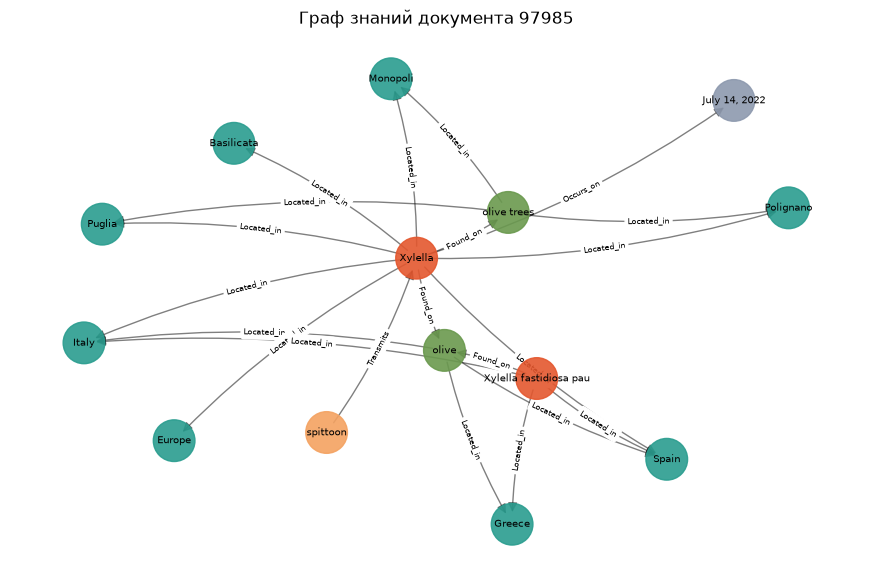

In [21]:
import matplotlib
import matplotlib.pyplot as plt

entity_type_colors = {
    "Pest": "#e4572e",
    "Plant": "#6a994e",
    "Disease": "#9b5de5",
    "Vector": "#f4a261",
    "Location": "#2a9d8f",
    "Date": "#8d99ae",
    "Dissemination_pathway": "#e9c46a",
}


def draw_kg(kg, path=None, max_edges=25):
    source_graph = kg.g
    edges = list(source_graph.edges(keys=True))[:max_edges]
    display_graph = nx.MultiDiGraph()
    display_graph.add_nodes_from(
        ((node, source_graph.nodes[node]) for edge in edges for node in edge[:2])
    )
    for subject, obj, predicate in edges:
        display_graph.add_edge(subject, obj, key=predicate)
    positions = nx.spring_layout(display_graph, seed=1, k=1.2)
    plt.figure(figsize=(11, 7))
    nx.draw_networkx_nodes(
        display_graph,
        positions,
        node_color=[
            entity_type_colors[display_graph.nodes[node]["type"]] for node in display_graph
        ],
        node_size=900,
        alpha=0.9,
    )
    nx.draw_networkx_labels(
        display_graph,
        positions,
        {node: display_graph.nodes[node]["label"][:22] for node in display_graph},
        font_size=7,
    )
    nx.draw_networkx_edges(
        display_graph,
        positions,
        arrows=True,
        arrowsize=14,
        alpha=0.5,
        connectionstyle=["arc3,rad=0.08", "arc3,rad=0.22", "arc3,rad=0.36"],
    )
    nx.draw_networkx_edge_labels(
        display_graph,
        positions,
        {
            (subject, obj, predicate): predicate
            for subject, obj, predicate in display_graph.edges(keys=True)
        },
        font_size=6,
        connectionstyle=["arc3,rad=0.08", "arc3,rad=0.22", "arc3,rad=0.36"],
    )
    plt.title(f"Граф знаний документа {kg.doc_id}")
    plt.axis("off")
    if path:
        plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


demo = max(document_graphs.values(), key=lambda k: min(k.g.number_of_edges(), 20))
draw_kg(demo, OUT + "kg_example.png")


In [22]:
# Сохраняем отдельный GraphML для каждого тестового документа и общий граф корпуса.
os.makedirs(OUT + "kg_graphml", exist_ok=True)
for k, kg in document_graphs.items():
    if kg.g.number_of_nodes():
        nx.write_graphml(kg.g, OUT + f"kg_graphml/{k}.graphml")
nx.write_graphml(corpus, OUT + "kg_graphml/_corpus.graphml")
print("Сохранено", len(os.listdir(OUT + "kg_graphml")), "файлов GraphML в", OUT + "kg_graphml/")


Сохранено 78 файлов GraphML в /Users/mansurzainullin/MyCode/fdd/spbu_dbdesign/outputs/fixed/kg_graphml/


## 13. Качество, ошибки и границы результата

Книга рассматривает качество как пригодность для конкретного использования и разделяет точность, охват, согласованность и краткость представления (гл. 7, печатные с. 119-124; PDF-страницы 139-144). Для нас полезно различать два уровня проверки. Валидность означает отсутствие нарушений заданных ограничений. Семантическая точность означает, что извлечённое утверждение верно по смыслу источника. Правильные типы концов и успешное чтение CSV не гарантируют второй уровень.

Здесь синтаксические и структурные проверки контролируют формат CSV, 20 сигнатур, сокращения, различение типов и ресурсов, сериализацию и происхождение рёбер. Для оценки извлечения используем независимые прогнозы и эталоны размеченной части. Считаем macro F1 по документам, а также precision, recall и F1 по предикатам. Precision показывает долю верных среди предсказанных отношений, recall долю найденных среди эталонных. Агрегированные micro-метрики складывают TP, FP и FN по документам, поэтому имеют другую систему весов, чем macro F1.

Для исправленного варианта micro precision составляет 0.5836, micro recall 0.4591. NER с точным совпадением границ и типа имеет OOF F1 0.7071. Это разные уровни цепочки, поэтому их нельзя непосредственно сравнивать как качество одной задачи.

Отдельно оцениваем потолок кандидатов: представим, что модель выбирает все правильные доступные кандидаты и ни одного неправильного. Такое oracle-предсказание использует эталон и не годится для нового текста. Потолок macro F1 составляет 0.7858, охват эталонных отношений кандидатами 0.6764. Это показывает, сколько ошибок нельзя исправить одним улучшением отбора отношений: нужной тройки уже нет среди кандидатов из-за NER, объединения или генерации пар. Сохранённые примеры пропущенного Dispersed_by разделяют случаи «кандидат отсутствовал» и «кандидат был, но модель или отбор его не выбрали». Это диагностика ограниченного набора ошибок, а не полная разметка всех причин.

Проверки разбиения и удаления внешней разметки контролируют независимость оценки. Проба с подменой эталонных полей подтверждает неизменность упоминаний. predict_document принимает только идентификатор, текст и пакет модели, поэтому эталонные поля документа не входят в её интерфейс. Восстановление модели и чтение GraphML обратно проверяют воспроизводимость результата. Протокол quality.json хранит метрики, настройки, версии и контрольную сумму кандидата; пользовательский результат Kaggle хранится отдельно в kaggle-validation.json.

Из этого можно заключить, что текущая цепочка воспроизводимо извлекает графы заданной схемы и имеет измеренное качество в описанных протоколах. Нельзя заключить, что она проверяет биологическую истинность всех фактов, полностью разрешает идентичность сущностей или восстанавливает все отношения из документа. Источники на рёбрах дают путь к проверке исходного текста, но не заменяют её.

Название «потолок» относится к диагностическому выбору по эталону среди текущих кандидатов и текущему локальному сопоставителю. Сопоставитель выбирает первое подходящее эталонное отношение; он не решает задачу максимального взаимно однозначного сопоставления. Поэтому число не заявляется как универсальный строгий максимум.

In [23]:
# Проверяем наблюдаемое поведение, в том числе восстановление сохранённых графов.
# Подмена разметки теста не должна менять упоминания, признаки и предсказания.
# Потолок кандидатов оцениваем, выбирая все верные кандидаты без ложных троек.
for index, validation in enumerate(folds):
    assert_separated([d for j, f in enumerate(folds) if j != index for d in f], validation)
assert len(SIGNATURES) == 20
full = "Tomato Brown Rugose Fruit Virus"
example_text = full + " (ToBRFV)"
example_mentions = [
    {"form": full, "type": "Pest", "start": 0, "end": len(full)},
    {"form": "ToBRFV", "type": "Pest", "start": len(full) + 2, "end": len(full) + 8},
]
assert (
    len(cluster(example_mentions, example_text, {(stem(full), "Pest"): ("NCBI", "1761477")})) == 1
)
homonyms = [{"form": "same", "type": ty, "start": 0, "end": 4} for ty in ("Pest", "Plant")]
assert len(cluster(homonyms, "same", {})) == 2
assert (
    len(
        cluster(
            [
                {"form": "same", "type": "Pest", "start": 0, "end": 4},
                {"form": "other", "type": "Pest", "start": 5, "end": 10},
            ],
            "same other",
            {("same", "Pest"): ("resource-a", "1"), ("other", "Pest"): ("resource-b", "1")},
        )
    )
    == 2
)
assert (
    f1_doc(
        [("Alpha", "found on", "Beta"), ("alpha", "FOUND_ON", "beta")],
        [(frozenset({"alpha"}), "Found_on", frozenset({"beta"}))],
    )
    == 1
)
assert f1_doc([], []) == 1 and f1_doc([("a", "Causes", "b")], []) == 0
assert f1_doc([], [(frozenset({"a"}), "Causes", frozenset({"b"}))]) == 0
assert f1_doc([("a2", "Causes", "b")], [(frozenset({"a", "a2"}), "Causes", frozenset({"b"}))]) == 1
base_arguments = [labelled_docs, computation_code, SETTINGS, FOLD_IDS, VERSIONS]
base_fingerprint = fingerprint(*base_arguments)
for index in range(5):
    changed = list(base_arguments)
    changed[index] = {"changed": True, "old": changed[index]}
    assert fingerprint(*changed) != base_fingerprint
with MODEL_FILE.open("rb") as stream:
    restored_bundle = pickle.load(stream)
for doc in test_docs:
    restored = predict_document(doc["doc_id"], doc["text"], restored_bundle)
    assert restored.triples() == document_graphs[doc["doc_id"]].triples()
for file in (Path(OUT) / "kg_graphml").glob("*.graphml"):
    restored = nx.read_graphml(file, force_multigraph=True)
    original = corpus if file.stem == "_corpus" else document_graphs[file.stem].g
    assert set(restored.nodes) == set(original.nodes)
    assert set(restored.edges(keys=True)) == set(original.edges(keys=True))
    for subject, obj, key, data in original.edges(keys=True, data=True):
        assert restored.edges[subject, obj, key]["predicate"] == data["predicate"]
        assert json.loads(restored.edges[subject, obj, key]["sources"]) == json.loads(
            data["sources"]
        )
for subject, obj, key, data in corpus.edges(keys=True, data=True):
    for doc_id in json.loads(data["sources"]):
        assert document_graphs[doc_id].g.has_edge(subject, obj, key)
assert "doc_id" not in corpus.graph
probe = test_docs[0]
poisoned = dict(
    probe,
    knowledge_graph=[{"subject": ["POISON"], "predicate": "Causes", "object": ["POISON"]}],
    text_bound_annotations={"entities": [{"type": "POISON"}]},
)
assert infer_mentions(final_ner, probe) == infer_mentions(final_ner, poisoned)
assert (
    predict_document(probe["doc_id"], probe["text"], restored_bundle).triples()
    == document_graphs[probe["doc_id"]].triples()
)


### Метрики и потери до выбора отношений

Считаем macro F1 по документам и micro precision/recall/F1 по суммарным TP, FP и FN. Потолок кандидатов отвечает на вопрос, какой результат возможен при идеальном выборе среди уже созданных кандидатов. Первые 20 пропусков Dispersed_by остаются исторической диагностикой; ниже добавлены отдельные иллюстративные примеры с фрагментами текста.

In [24]:
metrics = {}
error_examples = []
for algorithm, result in comparison.items():
    table = {}
    totals = [0, 0, 0]
    for predicate in PREDICATES:
        counts = [0, 0, 0]
        for doc in labelled_docs:
            predicted = [e for e in result["predictions"][doc["doc_id"]] if e[1] == predicate]
            gold = [e for e in gold_edges(doc) if e[1] == predicate]
            values = match_counts(predicted, gold)
            counts = [a + b for a, b in zip(counts, values)]
        tp, fp, fn = counts
        table[predicate] = {
            "tp": tp,
            "fp": fp,
            "fn": fn,
            "precision": tp / max(1, tp + fp),
            "recall": tp / max(1, tp + fn),
            "f1": 2 * tp / max(1, 2 * tp + fp + fn),
        }
        totals = [a + b for a, b in zip(totals, counts)]
    tp, fp, fn = totals
    metrics[algorithm] = {
        "macro_f1": result["macro_f1"],
        "micro_precision": tp / max(1, tp + fp),
        "micro_recall": tp / max(1, tp + fn),
        "micro_f1": 2 * tp / max(1, 2 * tp + fp + fn),
        "predicates": table,
    }
oracle_predictions = {}
candidate_hits = candidate_gold = 0
for doc in labelled_docs:
    doc_id = doc["doc_id"]
    gold = gold_edges(doc)
    available = {(m[2], m[1], m[3]) for m, _ in oof if m[0] == doc_id}
    true_candidates = [edge for edge in available if match_counts([edge], gold)[0]]
    oracle_predictions[doc_id] = true_candidates
    hits, _, missing = match_counts(true_candidates, gold)
    candidate_hits += hits
    candidate_gold += len(gold)
    if len(error_examples) < 20:
        predicted = selected_triples_by_document[doc_id]
        for subjects, predicate, objects in gold:
            if predicate != "Dispersed_by":
                continue
            if not any(
                (
                    predicate_key(p) == predicate_key(predicate)
                    and norm(s) in subjects
                    and (norm(o) in objects)
                    for s, p, o in predicted
                )
            ):
                reached = any(
                    (
                        p == predicate and norm(s) in subjects and (norm(o) in objects)
                        for s, p, o in available
                    )
                )
                error_examples.append(
                    {
                        "doc_id": doc_id,
                        "predicate": predicate,
                        "subjects": sorted(subjects),
                        "objects": sorted(objects),
                        "reason": "selection/model"
                        if reached
                        else "NER/normalization/candidate_generation",
                        "text_excerpt": doc["text"][:500],
                    }
                )
                if len(error_examples) >= 20:
                    break


### Подтверждение отправленного файла

Оценки Kaggle читаем из отдельного протокола пользователя. Они относятся к текущему CSV только при совпадении SHA256. Повторный запуск сохраняет протокол; иной файл не наследует его оценки.

In [25]:
def verified_kaggle_result(evidence, candidate_hash):
    """Оценка относится только к отправленному файлу с совпавшим хешем."""
    if evidence and evidence.get('sha256') == candidate_hash:
        return {'kaggle_candidate_score': evidence['public_score'],
                'kaggle_candidate_private_score': evidence['private_score'],
                'kaggle_status': 'confirmed_by_user_screenshot',
                'kaggle_evidence': evidence}
    return {'kaggle_candidate_score': None, 'kaggle_candidate_private_score': None,
            'kaggle_status': 'current_file_not_confirmed', 'kaggle_evidence': evidence}


KAGGLE_EVIDENCE_FILE = PROJECT_PATH / 'outputs/fixed/kaggle-validation.json'
kaggle_evidence = (json.loads(KAGGLE_EVIDENCE_FILE.read_text())
                   if KAGGLE_EVIDENCE_FILE.is_file() else None)
current_candidate_hash = hashlib.sha256(CANDIDATE_FILE.read_bytes()).hexdigest()
kaggle_result = verified_kaggle_result(kaggle_evidence, current_candidate_hash)
assert verified_kaggle_result(kaggle_evidence, 'другой хеш')['kaggle_candidate_score'] is None
assert verified_kaggle_result(None, current_candidate_hash)['kaggle_candidate_score'] is None
if kaggle_evidence:
    assert verified_kaggle_result(kaggle_evidence, kaggle_evidence['sha256'])['kaggle_candidate_score'] == kaggle_evidence['public_score']
print('Kaggle для текущего CSV:', kaggle_result['kaggle_status'],
      '| public:', kaggle_result['kaggle_candidate_score'],
      '| private:', kaggle_result['kaggle_candidate_private_score'])



Kaggle для текущего CSV: confirmed_by_user_screenshot | public: 0.5789 | private: 0.58085


In [26]:
quality_record = {
    "local_metric": "alias-set local matcher; not verified as official Kaggle scorer",
    "historical_dependent_macro_f1": 0.5428309298384271,
    "kaggle_public_reference": 0.38757,
    "kaggle_candidate_score": kaggle_result["kaggle_candidate_score"],
    "kaggle_status": kaggle_result["kaggle_status"],
    "comparison": metrics,
    "ner": ner_quality(combined_mentions, labelled_docs),
    "candidate_ceiling_macro_f1": score(oracle_predictions, labelled_docs),
    "candidate_gold_recall": candidate_hits / max(1, candidate_gold),
    "candidate_gold_hits": candidate_hits,
    "gold_edges": candidate_gold,
    "error_examples": error_examples,
    "cache_key": CACHE_KEY,
    "cache_hits": CACHE_HITS,
    "cache_misses": CACHE_MISSES,
    "candidate_sha256": hashlib.sha256(CANDIDATE_FILE.read_bytes()).hexdigest(),
    "test_documents": len(document_graphs),
    "test_triples": sum((len(g.triples()) for g in document_graphs.values())),
    "empty_test_graphs": sum((not g.triples() for g in document_graphs.values())),
    "checks": "passed",
    "versions": VERSIONS,
    "settings": SETTINGS,
}
quality_record.update(kaggle_result)
(Path(OUT) / "quality.json").write_text(json.dumps(quality_record, ensure_ascii=False, indent=2))
print(
    "Все проверки пройдены. Потолок кандидатов:",
    quality_record["candidate_ceiling_macro_f1"],
    "| полнота по эталону:",
    quality_record["candidate_gold_recall"],
)
print(pd.DataFrame(metrics["fixed"]["predicates"]).T.round(4))
print(
    "Хеш текущего CSV:", quality_record["candidate_sha256"]
)


Все проверки пройдены. Потолок кандидатов: 0.7858384803719921 | полнота по эталону: 0.6763546798029557
                 tp     fp     fn  precision  recall      f1
Affects        48.0   25.0   32.0     0.6575  0.6000  0.6275
Causes         43.0   12.0   28.0     0.7818  0.6056  0.6825
Dispersed_by    2.0   16.0   46.0     0.1111  0.0417  0.0606
Found_on      167.0   64.0  172.0     0.7229  0.4926  0.5860
Located_in    554.0  399.0  604.0     0.5813  0.4784  0.5249
Occurs_on     112.0  139.0  192.0     0.4462  0.3684  0.4036
Transmits       6.0   10.0   24.0     0.3750  0.2000  0.2609
Хеш текущего CSV: 16e56a8c69001a1ce659fb5a2267d3b11bc17c093071353436733c832b0b8215


## 14. Что можно спросить у полученного графа

Ниже используем предсказанные графы 82 тестовых документов. Запросы читают существующие рёбра и их источники. Число локаций относится к строковым узлам этого корпуса, а не к числу стран распространения вредителя. Для двухшагового пути проверяем, совпадают ли источники обоих рёбер. Полные ответы сохраняем, таблицы в выводе сокращаем для чтения.

In [27]:
ANALYSIS_DIR = Path(OUT) / 'report-analysis'
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
# Анализ использует только уже построенные графы и не обучает модели.
import textwrap
import hashlib
from collections import Counter
from matplotlib.patches import FancyBboxPatch

ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)

def analysis_corpus_snapshot():
    """Фиксируем содержимое графа, чтобы обнаружить случайное изменение при анализе."""
    return json.dumps({'graph': dict(corpus.graph),
                       'nodes': sorted((n, dict(a)) for n, a in corpus.nodes(data=True)),
                       'edges': sorted((s, o, k, dict(a)) for s, o, k, a in corpus.edges(keys=True, data=True))},
                      ensure_ascii=False, sort_keys=True)

analysis_before = analysis_corpus_snapshot()

def analysis_sources(attributes):
    """Читаем отсортированные идентификаторы исходных документов."""
    value = attributes.get('sources', [])
    return sorted(set(str(item) for item in (json.loads(value) if isinstance(value, str) else value)))

def analysis_graph(value):
    """Принимаем оболочку документного графа или сам граф NetworkX."""
    return value.g if hasattr(value, 'g') else value

analysis_documents = {str(key): analysis_graph(value) for key, value in document_graphs.items()}

def analysis_node(node_id):
    """Сохраняем подпись, тип и происхождение узла без изменения идентичности."""
    attributes = corpus.nodes[node_id]
    sources = analysis_sources(attributes)
    assert sources
    assert all(node_id in analysis_documents[doc_id] for doc_id in sources)
    return {'id': node_id, 'label': attributes['label'], 'type': attributes['type'], 'sources': sources}

def analysis_edge(subject, obj, predicate):
    """Каждое возвращённое ребро проверяем по всем заявленным документам."""
    attributes = corpus.edges[subject, obj, predicate]
    sources = analysis_sources(attributes)
    expected = sorted(doc_id for doc_id, graph in analysis_documents.items()
                      if graph.has_edge(subject, obj, key=predicate))
    assert sources == expected and sources
    assert attributes['predicate'] == predicate
    return {'subject': subject, 'predicate': predicate, 'object': obj, 'sources': sources}

def analysis_ordered_edges():
    return sorted(corpus.edges(keys=True))

# Паспорт отдельно считает документные тройки и уникальные рёбра объединения.
analysis_document_rows = []
for analysis_doc_id, analysis_g in sorted(analysis_documents.items()):
    analysis_document_rows.append({'doc_id': analysis_doc_id,
                                  'nodes': analysis_g.number_of_nodes(),
                                  'edges': analysis_g.number_of_edges(),
                                  'weak_components': nx.number_weakly_connected_components(analysis_g) if analysis_g.number_of_nodes() else 0,
                                  'empty': analysis_g.number_of_edges() == 0})
analysis_components = sorted((len(component) for component in nx.weakly_connected_components(corpus)), reverse=True)
analysis_passport = {
    'scope': 'Предсказанный тестовый корпус; качество этих связей по эталону не измерено',
    'candidate_sha256': hashlib.sha256(CANDIDATE_FILE.read_bytes()).hexdigest(),
    'documents': len(analysis_documents),
    'document_triples': sum(row['edges'] for row in analysis_document_rows),
    'nodes': corpus.number_of_nodes(), 'unique_edges': corpus.number_of_edges(),
    'empty_documents': sum(row['empty'] for row in analysis_document_rows),
    'isolated_nodes': len(list(nx.isolates(corpus))),
    'weak_components': len(analysis_components), 'weak_component_sizes': analysis_components,
    'largest_weak_component_nodes': analysis_components[0] if analysis_components else 0,
    'self_loops': nx.number_of_selfloops(corpus),
    'node_types': dict(sorted(Counter(a['type'] for _, a in corpus.nodes(data=True)).items())),
    'edge_predicates': dict(sorted(Counter(k for _, _, k in analysis_ordered_edges()).items())),
    'document_edge_predicates': dict(sorted(Counter(k for g in analysis_documents.values()
                                                  for _, _, k in g.edges(keys=True)).items())),
    'edge_source_multiplicity': dict(sorted(Counter(len(analysis_sources(a))
                                                   for _, _, _, a in corpus.edges(keys=True, data=True)).items())),
}

# Запрос 1: Pest с максимальным числом различных Location через Located_in.
analysis_location_options = []
for analysis_n, analysis_a in sorted(corpus.nodes(data=True)):
    if analysis_a['type'] != 'Pest':
        continue
    analysis_targets = sorted({o for _, o, k in corpus.out_edges(analysis_n, keys=True)
                               if k == 'Located_in' and corpus.nodes[o]['type'] == 'Location'})
    analysis_location_options.append((analysis_n, analysis_targets))
analysis_location_options.sort(key=lambda row: (-len(row[1]), row[0]))
analysis_location_winner = analysis_location_options[0] if analysis_location_options else None
analysis_query1 = {'rule': 'Максимум разных Location; при равенстве выбираем минимальный node_id',
                   'selected': None, 'count': 0, 'results': []}
if analysis_location_winner:
    analysis_n, analysis_targets = analysis_location_winner
    analysis_query1.update(selected=analysis_node(analysis_n), count=len(analysis_targets),
                           results=[{'location': analysis_node(o), 'edge': analysis_edge(analysis_n, o, 'Located_in')}
                                    for o in analysis_targets])

# Запрос 2: Plant с наибольшим числом разных Pest по входящим Found_on.
analysis_plant_options = []
for analysis_n, analysis_a in sorted(corpus.nodes(data=True)):
    if analysis_a['type'] != 'Plant':
        continue
    analysis_subjects = sorted({s for s, _, k in corpus.in_edges(analysis_n, keys=True)
                                if k == 'Found_on' and corpus.nodes[s]['type'] == 'Pest'})
    analysis_plant_options.append((analysis_n, analysis_subjects))
analysis_plant_options.sort(key=lambda row: (-len(row[1]), row[0]))
analysis_plant_winner = analysis_plant_options[0] if analysis_plant_options else None
analysis_query2 = {'rule': 'Максимум разных Pest; Vector не считается; при равенстве минимальный node_id',
                   'selected': None, 'count': 0, 'results': []}
if analysis_plant_winner:
    analysis_n, analysis_subjects = analysis_plant_winner
    analysis_query2.update(selected=analysis_node(analysis_n), count=len(analysis_subjects),
                           results=[{'pest': analysis_node(s), 'edge': analysis_edge(s, analysis_n, 'Found_on')}
                                    for s in analysis_subjects])

# Запрос 3: соединяем две наблюдаемые в графе связи, не добавляя третью.
def analysis_paths(first_types, first_predicate, second_type, second_predicate):
    """Перебираем все типизированные пути длины два и сравниваем источники рёбер."""
    results = []
    for subject, middle, predicate in analysis_ordered_edges():
        if predicate != first_predicate or (corpus.nodes[subject]['type'], corpus.nodes[middle]['type']) != first_types:
            continue
        for _, obj, next_predicate in sorted(corpus.out_edges(middle, keys=True)):
            if next_predicate != second_predicate or corpus.nodes[obj]['type'] != second_type:
                continue
            edges = [analysis_edge(subject, middle, predicate), analysis_edge(middle, obj, next_predicate)]
            common = sorted(set(edges[0]['sources']) & set(edges[1]['sources']))
            results.append({'nodes': [analysis_node(n) for n in (subject, middle, obj)],
                            'edges': edges, 'common_sources': common,
                            'source_mode': 'common_document' if common else 'disjoint_documents'})
    return results

analysis_path_results = analysis_paths(('Vector', 'Pest'), 'Transmits', 'Plant', 'Found_on')
analysis_path_kind = 'Vector → Transmits → Pest → Found_on → Plant'
if not analysis_path_results:
    analysis_path_results = analysis_paths(('Pest', 'Disease'), 'Causes', 'Plant', 'Affects')
    analysis_path_kind = 'Pest → Causes → Disease → Affects → Plant'
analysis_query3 = {'path': analysis_path_kind, 'count': len(analysis_path_results),
                   'common_document': [row for row in analysis_path_results if row['common_sources']],
                   'disjoint_documents': [row for row in analysis_path_results if not row['common_sources']],
                   'interpretation': 'Путь соединяет предсказанные рёбра. Он не доказывает новую биологическую связь.'}

# Примеры идентичности берём из результата, не объявляя похожие строки одной сущностью.
analysis_xylella_nodes = [analysis_node(n) for n in sorted(corpus.nodes)
                          if n in ('Pest:xylella', 'Pest:xylella fastidiosa')]
analysis_dirty_nodes = []
for analysis_type, analysis_preferred in (
    ('Location', ['Location:from east asia', 'Location:northern', 'Location:the', 'Location:eu']),
    ('Date', ['Date:first time', 'Date:on 31 august. 06/09/2022', 'Date:to date'])):
    analysis_available = [n for n in sorted(corpus.nodes) if corpus.nodes[n]['type'] == analysis_type]
    analysis_pick = next((n for n in analysis_preferred if n in corpus), None)
    if analysis_pick is None and analysis_available:
        analysis_pick = sorted(analysis_available, key=lambda n: (-len(corpus.nodes[n]['label']), n))[0]
    if analysis_pick:
        analysis_dirty_nodes.append(analysis_node(analysis_pick))
analysis_full = 'Tomato Brown Rugose Fruit Virus'
analysis_abbreviation_text = analysis_full + ' (ToBRFV)'
analysis_abbreviation_mentions = [
    {'form': analysis_full, 'type': 'Pest', 'start': 0, 'end': len(analysis_full)},
    {'form': 'ToBRFV', 'type': 'Pest', 'start': len(analysis_full) + 2, 'end': len(analysis_full) + 8}]
analysis_abbreviation_groups = cluster(analysis_abbreviation_mentions, analysis_abbreviation_text,
                                      {(stem(analysis_full), 'Pest'): ('NCBI', '1761477')})
assert len(analysis_abbreviation_groups) == 1
analysis_identity = [
    {'kind': 'observed_separate_nodes', 'nodes': analysis_xylella_nodes,
     'interpretation': 'Xylella и Xylella fastidiosa имеют разные node_id. Их таксономическую идентичность здесь не решаем.'},
    {'kind': 'observed_surface_noise', 'nodes': analysis_dirty_nodes,
     'interpretation': 'Узлы Location и Date сохраняют извлечённые строки; тип не гарантирует чистоту границ и нормализацию.'},
    {'kind': 'explicit_regression_example', 'text': analysis_abbreviation_text,
     'forms': [m['form'] for m in analysis_abbreviation_mentions],
     'concept_count': len(analysis_abbreviation_groups), 'reference': ['NCBI', '1761477'],
     'interpretation': 'Это явный проверочный пример cluster, а не найденная в тестовом графе пара. Полная форма и сокращение объединяются внутри документа по раскрытию и одной ссылке.'}]

assert analysis_corpus_snapshot() == analysis_before
analysis_record = {'passport': analysis_passport, 'documents': analysis_document_rows,
                   'queries': {'pest_locations': analysis_query1, 'plant_pests': analysis_query2,
                               'two_step_paths': analysis_query3}, 'identity_examples': analysis_identity,
                   'corpus_unchanged': True,
                   'provenance_checks': 'Все узлы и рёбра результатов проверены по исходным документным графам; источники рёбер совпадают с полным списком документов.'}
(ANALYSIS_DIR / 'analysis.json').write_text(json.dumps(analysis_record, ensure_ascii=False, indent=2, sort_keys=True) + '\n', encoding='utf-8')
pd.DataFrame(analysis_document_rows).to_csv(ANALYSIS_DIR / 'document-statistics.tsv', sep='\t', index=False)

# Небольшие схемы объясняют этапы; численные результаты берутся только из расчётов выше.
def analysis_draw_flow(filename, title, labels, subtitle, arrow_labels=None):
    """Рисуем читабельную горизонтальную схему без случайной раскладки."""
    with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 11}):
        fig, ax = plt.subplots(figsize=(13, 3.4))
        ax.set_xlim(0, len(labels)); ax.set_ylim(0, 1)
        for index, label in enumerate(labels):
            box = FancyBboxPatch((index + .07, .3), .86, .38,
                                 boxstyle='round,pad=0.025', facecolor='#edf3f8', edgecolor='#416782')
            ax.add_patch(box)
            ax.text(index + .5, .49, '\n'.join(textwrap.wrap(label, 19)), ha='center', va='center')
            if index < len(labels) - 1:
                ax.annotate('', xy=(index + 1.055, .49), xytext=(index + .955, .49),
                            arrowprops={'arrowstyle': '->', 'color': '#416782', 'lw': 1.8})
        if arrow_labels:
            for index, label in enumerate(arrow_labels):
                predicate_label, _, source_label = label.partition('\n')
                ax.text(index + 1, .77, predicate_label, ha='center', va='center', fontsize=10)
                ax.text(index + 1, .2, source_label, ha='center', va='center', fontsize=9)
        ax.set_title(title, fontsize=15, pad=14)
        ax.text(len(labels) / 2, .09, subtitle, ha='center', va='center', fontsize=10)
        ax.axis('off'); fig.tight_layout()
        fig.savefig(ANALYSIS_DIR / filename, dpi=180, bbox_inches='tight'); plt.close(fig)

analysis_draw_flow('pipeline.png', 'Как текст превращается в граф',
                   ['Текст документа', 'Упоминания и типы', 'Группы форм и кандидаты', 'Оценка и выбор связей', 'Граф с источниками'],
                   'Схема этапов. Рёбра остаются предсказаниями модели.')
# Вложенность разбиений показываем отдельно: общий рисунок скрывает источники признаков.
with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 10}):
    analysis_fig, analysis_ax = plt.subplots(figsize=(14, 7))
    analysis_ax.set_xlim(0, 14); analysis_ax.set_ylim(0, 7)
    def analysis_validation_box(x, y, width, height, label, color='#edf3f8', fontsize=10):
        analysis_ax.add_patch(FancyBboxPatch((x, y), width, height, boxstyle='round,pad=0.04',
                                            facecolor=color, edgecolor='#416782'))
        analysis_ax.text(x + width / 2, y + height / 2, label, ha='center', va='center', fontsize=fontsize)
    def analysis_validation_arrow(start, end):
        analysis_ax.annotate('', xy=end, xytext=start,
                             arrowprops={'arrowstyle': '->', 'color': '#416782', 'lw': 1.6})
    analysis_validation_box(.3, 5.6, 13.4, .8,
        '5 внешних разбиений по группам одинаковых текстов (хеш текста); seed = 0', '#e1edf6', 12)
    analysis_validation_arrow((7, 5.55), (7, 5.05))
    analysis_validation_box(.3, 2.7, 7.4, 2.3, '', '#f4f8fc')
    analysis_ax.text(4, 4.72, 'Обучающая часть внешнего разбиения', ha='center', fontsize=12)
    analysis_validation_box(.6, 3.25, 3.1, 1.05, '5 внутренних разбиений\nNER → отложенные упоминания\nдля обучающих документов')
    analysis_validation_box(4.35, 3.25, 3.0, 1.05, 'Кандидаты и признаки\n→ обучение LightGBM')
    analysis_validation_arrow((3.8, 3.78), (4.2, 3.78))
    analysis_validation_box(8.2, 2.7, 5.5, 2.3, '', '#f6f7ef')
    analysis_ax.text(10.95, 4.72, 'Проверочная часть внешнего разбиения', ha='center', fontsize=12)
    analysis_validation_box(8.55, 3.25, 2.1, 1.05, 'NER, обученный\nна внешней\nобучающей части')
    analysis_validation_box(11.15, 3.25, 2.2, 1.05, 'Предсказания связей\n→ выбор троек\n→ оценка по разметке')
    analysis_validation_arrow((10.7, 3.78), (11.05, 3.78))
    analysis_validation_arrow((7.8, 3.0), (11.2, 3.0))
    analysis_ax.text(9.5, 2.8, 'Модель связей', ha='center', fontsize=9)
    analysis_validation_box(.3, .65, 13.4, 1.25,
        'Словарь NER, ссылки форм (reference_map) и частоты связей (Priors): только внешняя обучающая часть.\n'
        'Проверочные документы не входят в обучение; эталон используется после предсказания.\n'
        'Внутренние предсказания упоминаний нужны для обучения модели связей, внешние предсказания дают локальную оценку.',
        '#fff7e8', 10)
    analysis_ax.set_title('Как устроена вложенная локальная проверка', fontsize=16, pad=14)
    analysis_ax.axis('off'); analysis_fig.tight_layout()
    analysis_fig.savefig(ANALYSIS_DIR / 'validation.png', dpi=180, bbox_inches='tight'); plt.close(analysis_fig)

# Показываем один реальный путь; полный ответ сохранён в JSON.
analysis_fragment_pool = analysis_query3['common_document'] or analysis_query3['disjoint_documents']
analysis_fragment = analysis_fragment_pool[0] if analysis_fragment_pool else None
if analysis_fragment:
    analysis_fragment_labels = [node['type'] + ': ' + node['label'] for node in analysis_fragment['nodes']]
    analysis_fragment_caption = 'Общие документы: ' + (', '.join(analysis_fragment['common_sources']) or 'нет')
else:
    analysis_fragment_labels = ['Начальный узел', 'Промежуточный узел', 'Конечный узел']
    analysis_fragment_caption = 'Таких путей в текущем графе нет. Показана только форма запроса.'
analysis_draw_flow('query-fragment.png', 'Фрагмент ответа на запрос длины два',
                   analysis_fragment_labels, analysis_fragment_caption,
                   [edge['predicate'] + '\nДокументы: ' + ', '.join(edge['sources'])
                    for edge in analysis_fragment['edges']] if analysis_fragment else None)

analysis_summary = '\n'.join([
    '# Анализ предсказанного графа', '',
    f"Тестовых документов: {analysis_passport['documents']}. Документных троек: {analysis_passport['document_triples']}. "
    f"Уникальных узлов: {analysis_passport['nodes']}, рёбер: {analysis_passport['unique_edges']}. "
    f"Пустых документных графов: {analysis_passport['empty_documents']}.", '',
    f"Запрос 1: {(analysis_query1['selected'] or {}).get('label', 'нет Pest')}, разных Location: {analysis_query1['count']}.", '',
    f"Запрос 2: {(analysis_query2['selected'] or {}).get('label', 'нет Plant')}, разных Pest: {analysis_query2['count']}.", '',
    f"Запрос 3: {analysis_query3['path']}. Путей: {analysis_query3['count']}; "
    f"с общим документом: {len(analysis_query3['common_document'])}, "
    f"с непересекающимися источниками: {len(analysis_query3['disjoint_documents'])}.", '',
    'Полные ответы с идентификаторами узлов и документами-источниками находятся в analysis.json. '
    'Документные числа сохранены также в document-statistics.tsv. '
    'При равных числах узел выбирается по лексикографическому порядку node_id.', '',
    'Все связи здесь предсказаны. Источник означает документ, в графе которого появилось ребро, '
    'а не независимую проверку его правильности. Путь из двух рёбер не добавляет нового факта. '
    'Объединение по типу и нормализованной строке не решает полную идентификацию сущностей.', ''])
(ANALYSIS_DIR / 'graph-summary.md').write_text(analysis_summary, encoding='utf-8')
assert analysis_corpus_snapshot() == analysis_before
print('Анализ графа сохранён:', ANALYSIS_DIR)
print(pd.Series(analysis_passport).drop(['scope', 'node_types', 'edge_predicates', 'document_edge_predicates', 'edge_source_multiplicity', 'weak_component_sizes']))


Анализ графа сохранён: /Users/mansurzainullin/MyCode/fdd/spbu_dbdesign/outputs/fixed/report-analysis
candidate_sha256                16e56a8c69001a1ce659fb5a2267d3b11bc17c09307135...
documents                                                                      82
document_triples                                                              975
nodes                                                                         437
unique_edges                                                                  737
empty_documents                                                                 5
isolated_nodes                                                                  0
weak_components                                                                 8
largest_weak_component_nodes                                                  415
self_loops                                                                      0
dtype: object


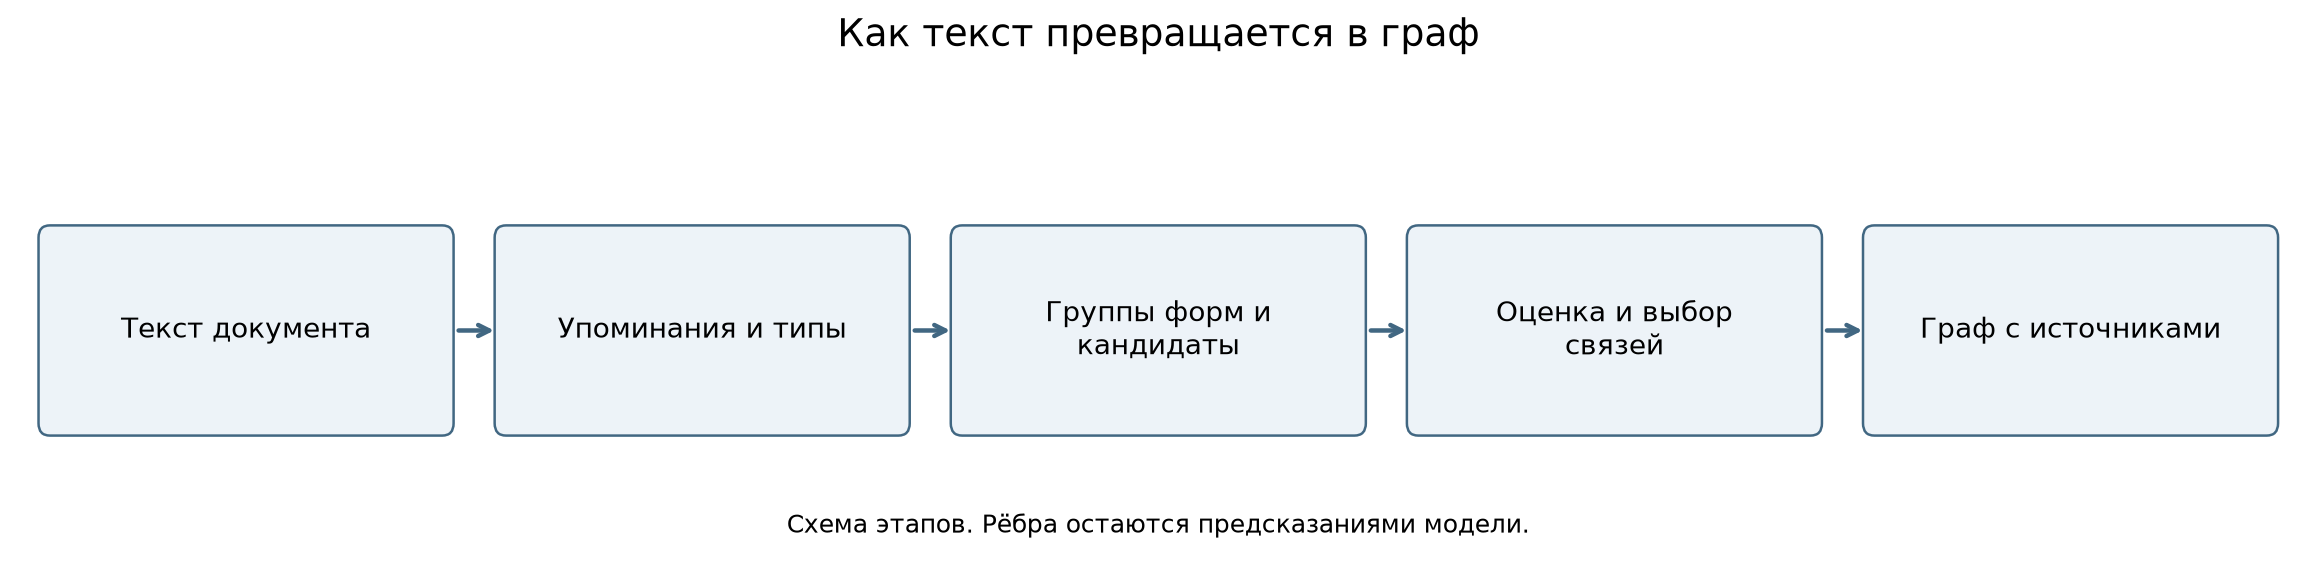

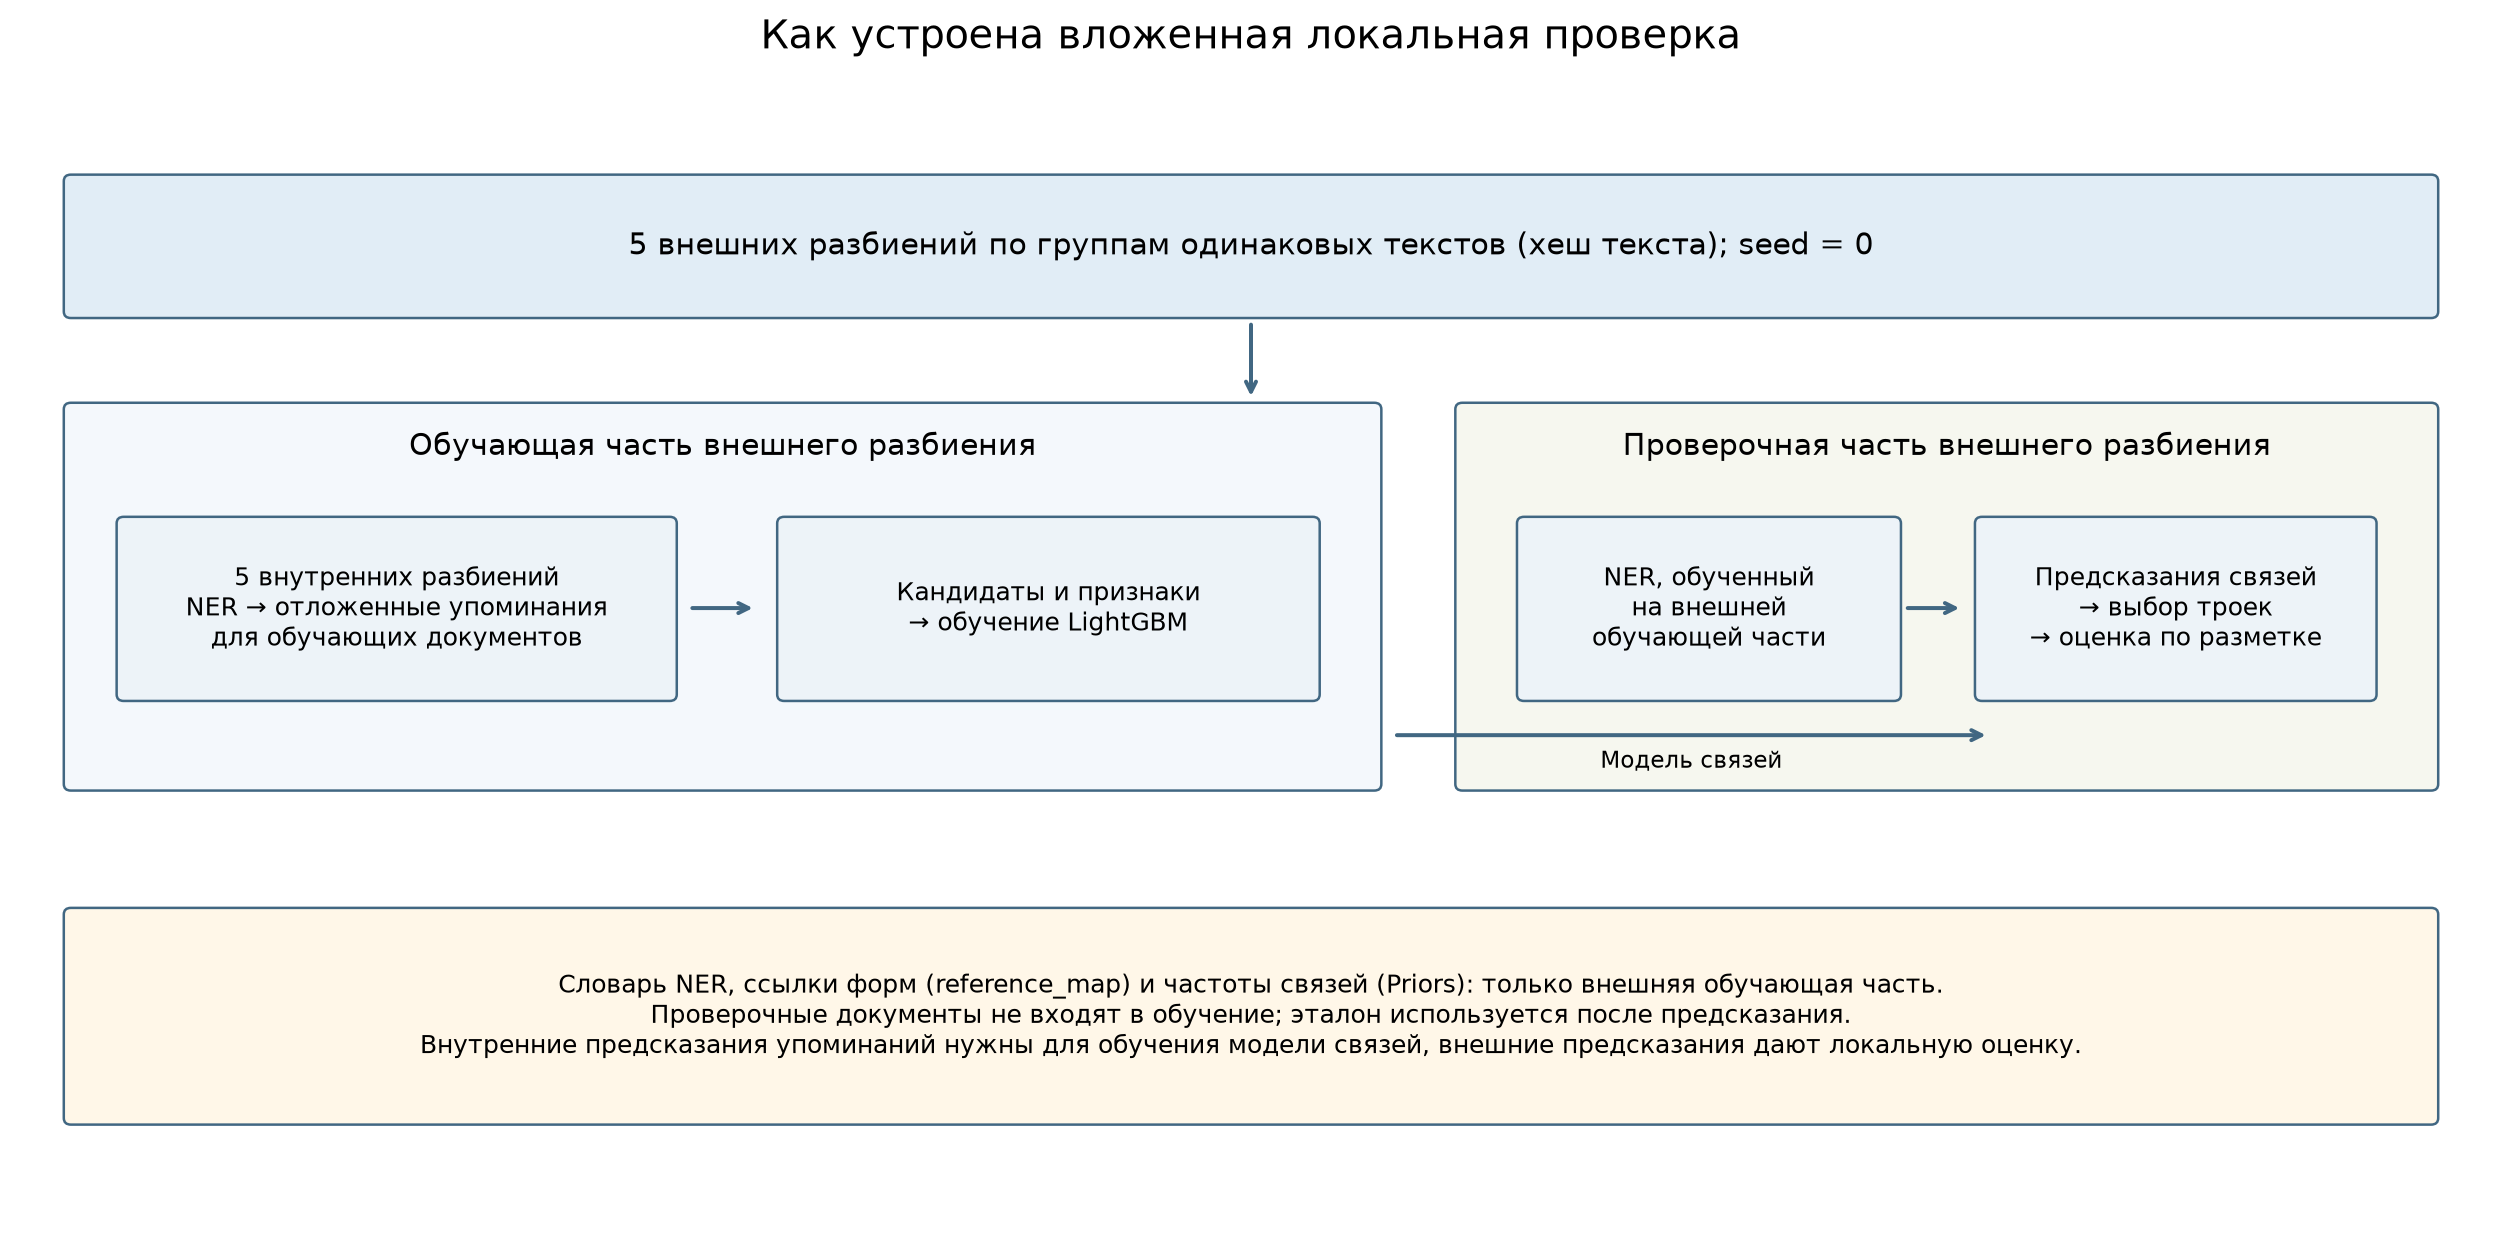

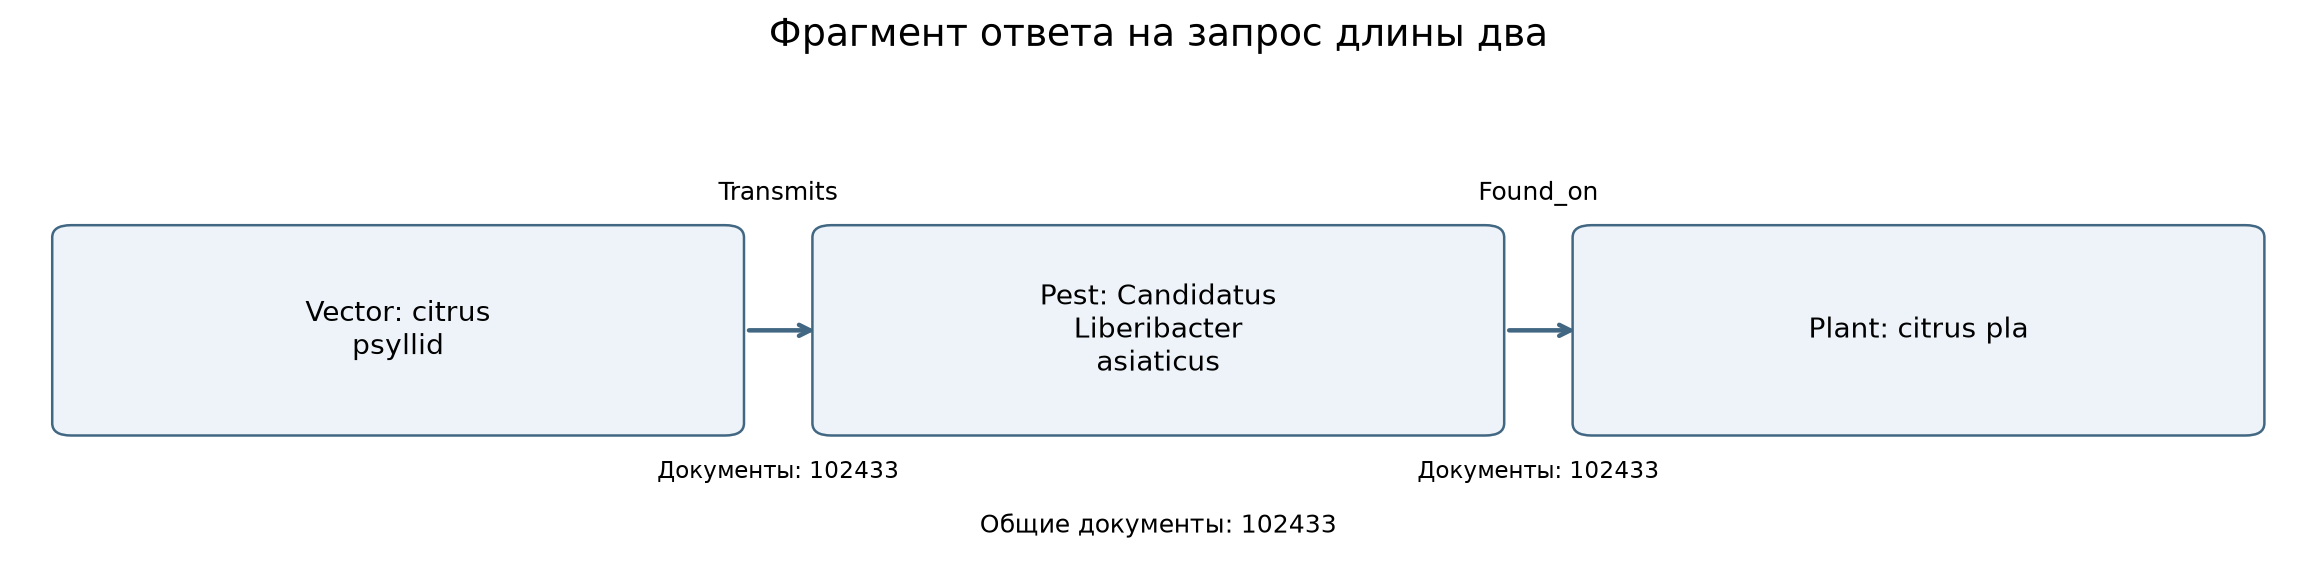

In [28]:
from IPython.display import Image, display
for filename in ['pipeline.png', 'validation.png', 'query-fragment.png']:
    display(Image(filename=str(ANALYSIS_DIR / filename)))


## 15. Сквозной пример и разбор внешних ошибок

В документе 104650 встречаются полное название Tomato Brown Rugose Fruit Virus и сокращение ToBRFV. Показываем упоминания, объединение форм, наиболее вероятные кандидаты и выбранные тройки. Признаки восстановлены из обучающей части его внешнего фолда; вероятности взяты из сохранённых внешних прогнозов. Эталон служит для сравнения и не участвует в этом предсказании.

Примеры TP/FP/FN выбираем детерминированно по id и порядку троек. Они объясняют возможные ошибки, но не представляют частоту ошибок всего корпуса. Для двух предикатов показываем TP, FP, пропущенную связь и отдельно связь, отсутствовавшую среди кандидатов. Поле candidate_reached показывает, дошла ли обычная пропущенная связь до этапа выбора отношений. Категория потерь до кандидатов объединяет несколько этапов и не доказывает отдельную ошибку CRF.

### Реальный пример: данные каждого шага

Этот фрагмент взят из документа 104650, смещения 0-253. Все числа ниже взяты из сохранённого внешнего прогноза в walkthrough.json.

> New Weed Hosts for Tomato Brown Rugose Fruit Virus in Wild Mediterranean Vegetation
> Tomato brown rugose fruit virus (ToBRFV; genus, Tobamovirus, family, Virgaviridae) was first reported in 2015 infecting tomatoes grown under protected cropping in the Jo

Первые найденные упоминания этого фрагмента:

| Форма | Тип | Начало | Конец |
|---|---|---:|---:|
| Tomato Brown Rugose Fruit Virus | Pest | 19 | 50 |
| Wild Mediterranean | Location | 54 | 72 |
| Tomato brown rugose fruit virus | Pest | 84 | 115 |
| ToBRFV | Pest | 117 | 123 |
| Tobamovirus | Pest | 132 | 143 |
| in 2015 | Date | 186 | 193 |
| tomatoes | Plant | 204 | 212 |
| Jordan Valley | Location | 251 | 264 |

Полное название, вариант его регистра и ToBRFV объединены в один концепт с 19 упоминаниями и ссылкой NCBI_Taxonomy:1761477. Самая частая форма ToBRFV стала канонической. Всего документ дал 38 упоминаний, 11 концептов, 36 кандидатов и 15 выбранных троек.

Для кандидата ToBRFV → Found_on → tomatoes модель получила, среди прочих, такие признаки:

| Признак | Значение |
|---|---:|
| subject_mentions | 19 |
| object_mentions | 5 |
| sentence_distance | 0 |
| paragraph_distance | 0 |
| same_sentence | 1 |
| same_paragraph | 1 |
| pair_prior | 5 |

Оценка этого кандидата: 0.931085. Он выбран. Это выход классификатора; вклад отдельных признаков и калибровку вероятности здесь не измеряем.

Одна из выбранных троек после графового слоя:

```json
{
  "predicate": "Found_on",
  "subject": "ToBRFV",
  "object": "tomatoes"
}
```

Полные векторы признаков, вероятности всех 36 кандидатов и все 15 троек находятся в [walkthrough.json](outputs/fixed/report-analysis/walkthrough.json). Дальше ячейка воспроизводит этот разбор и показывает примеры ошибок.

In [29]:
# Эти примеры читают результаты внешней проверки и не меняют предсказания.
def document_excerpt(text, subjects, objects, margin=130):
    """Возвращает фрагменты вокруг реально найденных форм и их смещения."""
    spans = []
    for role, forms in [('subject', subjects), ('object', objects)]:
        matches = []
        for form in forms:
            for match in re.finditer(re.escape(form), text, flags=re.IGNORECASE):
                matches.append((match.start(), match.end(), form))
        spans.append((role, sorted(matches)))
    subject_matches, object_matches = spans[0][1], spans[1][1]
    if subject_matches and object_matches:
        subject_match, object_match = min(
            ((left, right) for left in subject_matches for right in object_matches),
            key=lambda pair: (abs(pair[0][0] - pair[1][0]), pair[0][0], pair[1][0]))
        chosen = [subject_match, object_match]
    else:
        chosen = [matches[0] for _, matches in spans if matches]
    intervals = sorted((max(0, start-margin), min(len(text), end+margin))
                       for start, end, _ in chosen)
    merged = []
    for start, end in intervals:
        if merged and start <= merged[-1][1]:
            merged[-1][1] = max(merged[-1][1], end)
        else:
            merged.append([start, end])
    return [{'start': start, 'end': end, 'text': text[start:end]} for start, end in merged]


def outer_document_context(doc):
    """Восстанавливает подготовку документа только из обучающей части его фолда."""
    fold_index = next(index for index, validation in enumerate(folds)
                      if any(item['doc_id'] == doc['doc_id'] for item in validation))
    validation_ids = {item['doc_id'] for item in folds[fold_index]}
    training_docs = [item for item in labelled_docs if item['doc_id'] not in validation_ids]
    with (VERSION_CACHE / f'outer-{fold_index}-ner.pkl').open('rb') as stream:
        ner_bundle = pickle.load(stream)
    assert doc['doc_id'] not in ner_bundle['training_ids']
    mentions = infer_mentions(ner_bundle, unlabelled(doc))
    fold_references = build_ref_map(training_docs)
    fold_priors = Priors(training_docs)
    features, metadata = candidates(unlabelled(doc), mentions, fold_references, fold_priors,
                                    None, labels=False, trigger_vocab=TRIGGER_VOCAB)
    records = [(record, float(probability)) for record, probability in oof
               if record[0] == doc['doc_id']]
    assert [record for record, _ in records] == metadata
    return fold_index, mentions, fold_references, features, records


example_doc = next(doc for doc in labelled_docs if doc['doc_id'] == '104650')
example_fold, example_mentions, example_references, example_features, example_records = outer_document_context(example_doc)
example_concepts = cluster(example_mentions, example_doc['text'], example_references)
example_rows = []
for row_index in sorted(range(len(example_records)),
                        key=lambda index: (-example_records[index][1], index))[:8]:
    metadata, probability = example_records[row_index]
    triple = (metadata[2], metadata[1], metadata[3])
    example_rows.append({'triple': list(triple), 'probability': probability,
                         'selected': triple in selected_triples_by_document[example_doc['doc_id']],
                         'features': {name: float(value) for name, value in
                                      zip(model_bundle['feature_names'], example_features[row_index])}})
walkthrough = {
    'doc_id': example_doc['doc_id'], 'outer_fold': example_fold,
    'note': 'Все упоминания, признаки и вероятности относятся к независимому внешнему прогнозу. Эталон нужен только для сравнения.',
    'excerpt': document_excerpt(example_doc['text'], ['Tomato brown rugose fruit virus'], ['ToBRFV']),
    'mentions': example_mentions,
    'concepts': [{'type': concept['type'], 'identity': concept['key'],
                  'forms': dict(concept['forms']), 'mentions': concept['ms']}
                 for concept in example_concepts],
    'top_candidates': example_rows,
    'all_candidate_probabilities': [{'subject': record[2], 'predicate': record[1],
                                      'object': record[3], 'probability': probability}
                                     for record, probability in example_records],
    'selected_triples': [list(triple) for triple in selected_triples_by_document[example_doc['doc_id']]],
    'graph_json': validation_graphs[example_doc['doc_id']].triples(),
    'gold': example_doc['knowledge_graph']}
assert {(norm(subject), predicate, norm(obj)) for subject, predicate, obj in walkthrough['selected_triples']} == {
    (norm(triple['subject']), triple['predicate'], norm(triple['object'])) for triple in walkthrough['graph_json']}
(ANALYSIS_DIR / 'walkthrough.json').write_text(json.dumps(walkthrough, ensure_ascii=False, indent=2))
print('Сквозной пример, документ', example_doc['doc_id'], 'внешний фолд', example_fold)
display(pd.DataFrame([{key: value for key, value in row.items() if key != 'features'} for row in example_rows]))
display(pd.DataFrame([{'Тип': concept['type'], 'Формы': ', '.join(concept['forms']),
                       'Идентификатор': str(concept['identity'])} for concept in walkthrough['concepts']
                      if any('tobrfv' in form.lower() or 'brown rugose' in form.lower() for form in concept['forms'])]))

# Выбор первых примеров по id и тройке воспроизводим, но не представляет все ошибки.
illustrative_cases = []
for predicate in ['Located_in', 'Dispersed_by']:
    for category in ['TP', 'FP', 'FN', 'FN_before_candidates']:
        found_case = None
        for doc in sorted(labelled_docs, key=lambda item: item['doc_id']):
            predicted = sorted(triple for triple in selected_triples_by_document[doc['doc_id']]
                               if triple[1] == predicate)
            gold = [edge for edge in gold_edges(doc) if edge[1] == predicate]
            if category in ['TP', 'FP']:
                edge = next((edge for edge in predicted
                             if bool(match_counts([edge], gold)[0]) == (category == 'TP')), None)
                if edge is None:
                    continue
                subjects, objects = [edge[0]], [edge[2]]
            else:
                missing = next((edge for edge in gold
                                if not any(norm(subject) in edge[0] and norm(obj) in edge[2]
                                           for subject, _, obj in predicted)), None)
                if category == 'FN_before_candidates':
                    available_edges = [(record[2], record[1], record[3]) for record, _ in oof
                                       if record[0] == doc['doc_id'] and record[1] == predicate]
                    missing = next((edge for edge in gold
                                    if not match_counts(predicted, [edge])[0]
                                    and not match_counts(available_edges, [edge])[0]), None)
                if missing is None:
                    continue
                subjects, objects = sorted(missing[0]), sorted(missing[2])
            available = [(record, float(probability)) for record, probability in oof
                         if record[0] == doc['doc_id'] and record[1] == predicate
                         and norm(record[2]) in {norm(form) for form in subjects}
                         and norm(record[3]) in {norm(form) for form in objects}]
            fold_index, mentions, _, _, _ = outer_document_context(doc)
            found_case = {'doc_id': doc['doc_id'], 'outer_fold': fold_index,
                          'category': category, 'predicate': predicate,
                          'subjects': subjects, 'objects': objects,
                          'candidate_reached': bool(available),
                          'candidate_probabilities': [probability for _, probability in available],
                          'stage': ('до кандидатов: NER, нормализация или схема' if category.startswith('FN') and not available
                                    else 'выбор отношений' if category.startswith('FN') else 'сравнение с эталоном'),
                          'excerpts': document_excerpt(doc['text'], subjects, objects),
                          'predicted_mentions': mentions,
                          'gold_edges': doc['knowledge_graph']}
            break
        assert found_case is not None, f'Нет примера {predicate}/{category}'
        illustrative_cases.append(found_case)
(ANALYSIS_DIR / 'error-cases.json').write_text(json.dumps(illustrative_cases, ensure_ascii=False, indent=2))
display(pd.DataFrame([{key: value for key, value in case.items()
                       if key in ['doc_id', 'category', 'predicate', 'subjects', 'objects', 'candidate_reached', 'stage']}
                      for case in illustrative_cases]))


Сквозной пример, документ 104650 внешний фолд 2


,triple,probability,selected
0,"[ToBRFV, Found_on, tomatoes]",0.931085,True
1,"[ToBRFV, Located_in, Jordan Valley]",0.916850,True
2,"[Tobamovirus, Located_in, Jordan Valley]",0.863106,True
3,"[tomatoes, Located_in, Jordan Valley]",0.821680,True
4,"[ToBRFV, Found_on, Solanum nigrum]",0.817843,True
5,"[ToBRFV, Located_in, Wild Mediterranean]",0.746665,True
6,"[ToBRFV, Located_in, Jordan]",0.740216,True
7,"[ToBRFV, Found_on, Malva parviflora]",0.734098,True


,Тип,Формы,Идентификатор
0,Pest,"Tomato Brown Rugose Fruit Virus, Tomato brown ...","('NCBI_Taxonomy', '1761477')"


,doc_id,category,predicate,subjects,objects,candidate_reached,stage
0,100011,TP,Located_in,[Japanese beetle],[Asia],True,сравнение с эталоном
1,100011,FP,Located_in,[Japanese beetle],[Europe],True,сравнение с эталоном
2,100011,FN,Located_in,[freight],"[freiburg, freiburg area]",True,выбор отношений
3,100018,FN_before_candidates,Located_in,"[japanese beetle, popilia japonica, popilias]",[genestrerio],False,"до кандидатов: NER, нормализация или схема"
4,117923,TP,Dispersed_by,[FAW],[wind],True,сравнение с эталоном
5,100461,FP,Dispersed_by,[Japanese beetle],[freight],True,сравнение с эталоном
6,100020,FN,Dispersed_by,"[japanese beetle, japanese beetles, popillia j...",[freight],True,выбор отношений
7,104650,FN_before_candidates,Dispersed_by,"[tobrfv, tomato brown rugose fruit virus]",[seed],False,"до кандидатов: NER, нормализация или схема"


## 16. От ответа графа обратно к тексту

Сравним два ответа запроса о Xylella. Для связи с Monopoli текст прямо сообщает о заражённых деревьях. Для связи с Нидерландами выбранный фрагмент говорит об университете. Это ручное чтение двух примеров, не новая оценка всего test; предсказания и CSV после него не меняем.

In [30]:
# Ручной разбор двух ответов первого запроса; это не оценка всего test-корпуса.
source_audit_specs = [
    {'doc_id': '97985', 'subject_node': 'Pest:xylella', 'object_node': 'Location:monopoli',
     'anchor': 'There are 30 olive trees infected',
     'assessment': 'Фрагмент прямо сообщает о заражённых Xylella оливковых деревьях в Monopoli. Это поддерживает чтение Located_in для этого документа.',
     'status': 'поддерживается выбранным фрагментом'},
    {'doc_id': '102892', 'subject_node': 'Pest:xylella', 'object_node': 'Location:netherlands',
     'anchor': 'researchers led by economists',
     'assessment': 'The Netherlands относится к местонахождению University of Wageningen и исследователей. Этот фрагмент не сообщает, что Xylella обнаружена в Нидерландах. Предсказанное ребро выглядит сомнительным; эталона test у нас нет.',
     'status': 'сомнительное отношение: место учреждения'}]
source_audits = []
for specification in source_audit_specs:
    doc = next(item for item in test_docs if item['doc_id'] == specification['doc_id'])
    subject, obj = specification['subject_node'], specification['object_node']
    assert any(row['edge']['subject'] == subject and row['edge']['object'] == obj
               for row in analysis_record['queries']['pest_locations']['results'])
    edge = analysis_edge(subject, obj, 'Located_in')
    assert doc['doc_id'] in edge['sources']
    anchor = doc['text'].index(specification['anchor'])
    start, end = max(0, anchor-100), min(len(doc['text']), anchor+370)
    source_audits.append({**specification, 'edge': edge,
                          'triple': {'subject': corpus.nodes[subject]['label'], 'predicate': 'Located_in',
                                     'object': corpus.nodes[obj]['label']},
                          'excerpt': {'start': start, 'end': end, 'text': doc['text'][start:end]},
                          'gold_available': False})
(ANALYSIS_DIR / 'source-audits.json').write_text(json.dumps(source_audits, ensure_ascii=False, indent=2))
for audit in source_audits:
    print('\nДокумент', audit['doc_id'], '|', audit['triple'], '\n', audit['excerpt']['text'],
          '\nРазбор:', audit['assessment'])



Документ 97985 | {'subject': 'Xylella', 'predicate': 'Located_in', 'object': 'Monopoli'} 
 d Basilicata Monitoring An olive tree felled due to xylella fastidiosa July 14, 2022 Online editing There are 30 olive trees infected by Xylella in Monopoli and 9 in Polignano a Mare, at the third monitoring started in May 2022. In less than two months 59 diseased trees have been found. This is what Coldiretti Puglia reports, based on Infoxylella data, following the update of the dashboard of the 'Emergency Xylellà' institutional website of the Puglia Region. 31 dis 
Разбор: Фрагмент прямо сообщает о заражённых Xylella оливковых деревьях в Monopoli. Это поддерживает чтение Located_in для этого документа.

Документ 102892 | {'subject': 'Xylella', 'predicate': 'Located_in', 'object': 'Netherlands'} 
 taly, Greece and Spain, study carried out within the Project H2020 POnTE by a multinational team of researchers led by economists from the University of Wageningen (The Netherlands). The infection of 

## Что подготовлено и что остаётся за пределами работы

Рабочий результат: воспроизводимая цепочка извлечения, пакет модели, CSV для 82 документов и графы с источниками. Независимая локальная проверка исправленного варианта даёт macro F1 0.5329005742695576. Пользовательская отправка актуального кандидата подтверждает public 0.57890 и private 0.58085. Эти результаты нельзя смешивать: они относятся к разным выборкам и процедурам сопоставления.

Графовая часть задаёт типы, допустимые связи, объединение форм и происхождение извлечённых утверждений. Преобразование выбранных троек в граф сохраняет их множество и не повышает F1 само по себе. Обучающие частоты помогают классификатору помнить повторения корпуса; это не результат рассуждения по графу. Правила вывода новых связей и проверка биологической истинности не реализованы.

Ограничения относятся к конкретным шагам. CRF может пропустить сущность или ошибиться в границах. Словари помогают знакомым формам. Нормализация зависит от доступной разметки и шаблона сокращений. Схема исключает неподходящие типы, но не опровергает смысловую ошибку. LightGBM и приближённый выбор набора могут пропустить доступное правильное ребро. Объединение графов по строкам не решает все междокументные неоднозначности.

Для подготовки презентации уже есть описание этапов, карта теории и реализации, протокол качества, независимые метрики и примеры ошибок. По ним можно объяснить, как построен результат и почему утверждения ограничены описанными проверками. Нового алгоритма или неподтверждённого прироста от графового вывода в этой работе нет.

Материалы для отдельного агента: [разбор графа](../GRAPH_ANALYSIS.md), [пакет передачи](../PRESENTATION_HANDOFF.md), [индекс](../INDEX.md). Презентация в этой работе не создавалась.

## 17. Проверка сохранения подтверждённого результата

Редакционные изменения и запросы не должны менять CSV и локальные метрики. Последняя ячейка проверяет побайтовое совпадение отправленного файла, числовые результаты и сохранность внешнего протокола.

In [31]:
# Редакционный рефакторинг должен сохранить уже отправленный файл и метрики.
REFERENCE_DIR = PROJECT_PATH.parent / 'output/jupyter-notebook/pestclef-report/before-report'
reference_quality = json.loads((REFERENCE_DIR / 'spbu_dbdesign/outputs/fixed/quality.json').read_text())
assert CANDIDATE_FILE.read_bytes() == (REFERENCE_DIR / 'spbu_dbdesign/outputs/fixed/submission_candidate.csv').read_bytes()
assert current_candidate_hash == '16e56a8c69001a1ce659fb5a2267d3b11bc17c093071353436733c832b0b8215'
for algorithm in ['legacy', 'fixed']:
    for key in ['macro_f1', 'micro_precision', 'micro_recall', 'micro_f1']:
        assert abs(metrics[algorithm][key] - reference_quality['comparison'][algorithm][key]) <= 1e-12
    assert metrics[algorithm]['predicates'] == reference_quality['comparison'][algorithm]['predicates']
for key in ['candidate_ceiling_macro_f1', 'candidate_gold_recall']:
    assert abs(quality_record[key] - reference_quality[key]) <= 1e-12
assert quality_record['ner'] == reference_quality['ner']
assert kaggle_result['kaggle_candidate_score'] == .57890
assert kaggle_result['kaggle_candidate_private_score'] == .58085
assert json.loads(KAGGLE_EVIDENCE_FILE.read_text()) == kaggle_evidence
acceptance = {'csv_byte_equal': True, 'metrics_equal': True, 'tolerance': 1e-12,
              'candidate_sha256': current_candidate_hash, 'kaggle_evidence_preserved': True,
              'cache_key': CACHE_KEY, 'cache_hits': CACHE_HITS, 'cache_misses': CACHE_MISSES}
(ANALYSIS_DIR / 'acceptance.json').write_text(json.dumps(acceptance, ensure_ascii=False, indent=2))
print('Версия принята: CSV побайтово совпал; локальные метрики и подтверждение Kaggle сохранены.')


Версия принята: CSV побайтово совпал; локальные метрики и подтверждение Kaggle сохранены.
